# Echo — Growth Modeling & Data-Driven Strategy (IMT 2026 final project)

**Board question: should Echo roll out aggressive push notifications to everyone?**

## 0. Setup

In [1]:
import warnings
warnings.filterwarnings('ignore', category=FutureWarning)
from pathlib import Path
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from matplotlib.colors import LinearSegmentedColormap
from scipy import stats
from IPython.display import display, Markdown

pd.set_option('display.width', 160)
pd.set_option('display.max_columns', 40)
pd.set_option('display.float_format', lambda x: f'{x:,.3f}')

DATA = Path('data')
OUT = Path('outputs'); FIG = OUT / 'figures'; CLEAN = OUT / 'clean'
for p in (FIG, CLEAN):
    p.mkdir(parents=True, exist_ok=True)

# Constants
CPM = 9.0  # 9€ per 1000 ads
REV_PER_AD = CPM / 1000  # € per ad impression
EXTRACTION = pd.Timestamp('2026-06-30')  # date of data extraction
LAST_FULL_WEEK = pd.Timestamp('2026-06-22')  # Work on full weeks to avoid partial weeks at the end
TEST_START, TEST_END = pd.Timestamp('2026-01-15'), pd.Timestamp('2026-03-15')
CHANNELS = ['organic_store', 'paid_social', 'podcast_cross_promo']

# Color palette
BLUE, ORANGE, AQUA, YELLOW = '#2a78d6', '#eb6834', '#1baf7a', '#eda100'
GRAY, INK, INK2, SURFACE = '#9a9994', '#0b0b0b', '#52514e', '#fcfcfb'
CH_COLORS = {'organic_store': BLUE, 'paid_social': ORANGE, 'podcast_cross_promo': AQUA}
AB_COLORS = {'control': BLUE, 'aggressive_push': ORANGE}
SEQ = LinearSegmentedColormap.from_list('seq_blue', ['#cde2fb', '#86b6ef', '#3987e5', '#256abf', '#184f95', '#0d366b'])

plt.rcParams.update({
    'figure.figsize': (9, 4.2), 'figure.dpi': 110, 'font.size': 10,
    'axes.spines.top': False, 'axes.spines.right': False, 'axes.edgecolor': '#d9d8d4',
    'axes.grid': True, 'grid.color': '#ecebe8', 'grid.linewidth': 0.6, 'axes.axisbelow': True,
    'axes.titlesize': 12, 'axes.titleweight': 'bold', 'axes.titlelocation': 'left',
    'axes.labelcolor': INK2, 'xtick.color': INK2, 'ytick.color': INK2, 'text.color': INK,
    'lines.linewidth': 2, 'legend.frameon': False,
    'figure.facecolor': SURFACE, 'axes.facecolor': SURFACE, 'savefig.facecolor': SURFACE, 'savefig.bbox': 'tight',
})

def save(fig, name):
    fig.savefig(FIG / f'{name}.png', dpi=150)

def end_label(ax, x, y, text):
    """Direct label at the end of a line (text in ink colour, never the series colour)."""
    ax.annotate(text, (x, y), xytext=(5, 0), textcoords='offset points', va='center', fontsize=9, color=INK2)

def end_labels(ax, x, items, min_gap_frac=0.05):
    """Several end-of-line labels, nudged vertically so they never overlap. items = [(y, text), ...]"""
    lo, hi = ax.get_ylim(); gap = (hi - lo) * min_gap_frac
    placed = []
    for y, text in sorted(items):
        y_txt = max(y, placed[-1] + gap) if placed else y
        placed.append(y_txt)
        ax.annotate(text, (x, y), xytext=(x, y_txt), textcoords='data', va='center', fontsize=9, color=INK2,
                    annotation_clip=False)

def pct(x, d=1):
    return f'{100 * x:.{d}f} %'

## 1. Data exploration

First we are going to check the dimension of the datasets.

In [2]:
users_raw = pd.read_csv(DATA / 'users.csv')
weekly_raw = pd.read_csv(DATA / 'weekly_activity.csv')
spend_raw = pd.read_csv(DATA / 'marketing_spend.csv')

for name, df in {'users': users_raw, 'weekly_activity': weekly_raw, 'marketing_spend': spend_raw}.items():
    print(f'{name}: {df.shape}')
print(f'Total rows: {len(users_raw) + len(weekly_raw) + len(spend_raw)}')

users: (20909, 7)
weekly_activity: (334399, 6)
marketing_spend: (17, 3)
Total rows: 355325


We find `355325` total rows, the same number presented in the data pack.

In [3]:
def profile(df):
    return pd.DataFrame({
        'dtype': df.dtypes.astype(str),
        'missing': df.isna().sum(),
        'unique': df.nunique(),
        'example': df.iloc[0]})

display(users_raw.head())
display(profile(users_raw))
print('Exact duplicate rows:', users_raw.duplicated().sum(), '| duplicated user_id:', users_raw.user_id.duplicated().sum())

,user_id,signup_date,acquisition_channel,platform,age_bucket,push_variant,shows_followed_week1
0,U004452,2025-05-29,podcast_cross_promo,Android,35-44,standard,2
1,U006707,2025-08-09,paid_social,iOS,25-34,standard,2
2,U016164,2026-03-01,podcast_cross_promo,iOS,NaN,aggressive_push,1
3,U011607,2025-12-20,organic_store,Android,45+,standard,1
4,U001940,2025-03-14,paid_social,Android,25-34,standard,2


,dtype,missing,unique,example
user_id,object,0,20785,U004452
signup_date,object,0,780,2025-05-29
acquisition_channel,object,0,3,podcast_cross_promo
platform,object,0,2,Android
age_bucket,object,660,4,35-44
push_variant,object,0,6,standard
shows_followed_week1,int64,0,12,2


Exact duplicate rows: 124 | duplicated user_id: 124


Few duplicates (the duplicates are full line ducplicates) and only `age_bucket` have missing values (not an important column so we can keep them).

In [4]:
for col in ['acquisition_channel', 'platform', 'age_bucket', 'push_variant', 'shows_followed_week1']:
    print(users_raw[col].value_counts(dropna=False).to_string(), '\n')

acquisition_channel
paid_social            8950
organic_store          7722
podcast_cross_promo    4237 

platform
Android    10496
iOS        10413 

age_bucket
25-34    7043
18-24    5964
35-44    4143
45+      3099
NaN       660 

push_variant
standard           18181
control             1276
aggressive_push     1240
Control              100
AGGRESSIVE_PUSH       58
aggressive            54 

shows_followed_week1
2     5293
1     5167
3     3956
0     2514
4     2229
5     1100
6      440
7      153
8       40
9       13
11       3
12       1 



We can see the distribution of values in the different columns. This highlight that the `push_variant` column have different values for the same meaning (ex: `aggressive_push` / `AGGRESSIVE_PUSH` / `aggressive`), they will be merged later.

Then we check for date formats in `signup_date` (digits replaced by ? to reveal the patterns):

In [5]:
print(users_raw.signup_date.str.replace(r'\d', '?', regex=True).value_counts())

signup_date
????-??-??    20595
??/??/????      314
Name: count, dtype: int64


The majority format is `xxxx-xx-xx`, only a few exception with the `xx/xx/xxxx` format will need to be reformated.

In [6]:
display(weekly_raw.head())
display(profile(weekly_raw))
print('Exact duplicate rows:', weekly_raw.duplicated().sum(), ' | duplicated user_id: ', weekly_raw.user_id.duplicated().sum())
print('week_start formats:', weekly_raw.week_start.str.replace(r'\d', '?', regex=True).value_counts().to_dict())
display(weekly_raw.describe())

,user_id,week_start,sessions,listening_minutes,ad_impressions,push_notifications_received
0,U014739,2026-06-08,1,21.400,3,25
1,U002742,2025-04-28,3,70.700,10,8
2,U015251,2026-04-13,3,59.100,9,41
3,U008670,2025-09-08,6,94.500,16,3
4,U004384,2025-07-28,5,81.900,14,3


,dtype,missing,unique,example
user_id,object,0,20785,U014739
week_start,object,0,79,2026-06-08
sessions,int64,0,18,1
listening_minutes,float64,0,3801,21.400
ad_impressions,int64,0,69,3
push_notifications_received,int64,0,55,25


Exact duplicate rows: 1663  | duplicated user_id:  313614
week_start formats: {'????-??-??': 334399}


,sessions,listening_minutes,ad_impressions,push_notifications_received
count,"334,399.000","334,399.000","334,399.000","334,399.000"
mean,3.511,114.526,11.563,5.255
std,1.845,"1,737.446",6.883,6.231
min,1.000,-1.000,1.000,0.000
25%,2.000,42.400,6.000,3.000
50%,3.000,70.100,10.000,4.000
75%,5.000,107.200,15.000,6.000
max,21.000,"99,999.000",82.000,58.000


There are few duplicated rows (1663) we will drop them later. The duplicated `user_id` is normal because this table tracks the same users over time. The date format in `week_start` is consistent. However `listening_minutes` has a minimum of −1 and a maximum of 99,999, there seems to be errors / outliers.

We can check for the extreme values we find and their quantity:

In [7]:
lm = weekly_raw.listening_minutes
print('Negatives :', lm[lm <= 0].value_counts().to_dict())
print('Values > 1000:', lm[lm > 1000].value_counts().to_dict())

Negatives : {-1.0: 96}
Values > 1000: {10080.0: 105, 99999.0: 100}


The quantity of negatives and the quantity of impossibly high values are both very small. We can drop these entries later to avoid polluting the analysis.

In [8]:
display(spend_raw.head())
display(profile(spend_raw))

,month,channel,spend_eur
0,2025-01-01,paid_social,990.000
1,2025-02-01,paid_social,"1,020.000"
2,2025-03-01,paid_social,"1,050.000"
3,2025-04-01,paid_social,"1,080.000"
4,2025-06-01,paid_social,"1,150.000"


,dtype,missing,unique,example
month,object,0,17,2025-01-01
channel,object,0,1,paid_social
spend_eur,float64,0,17,990.000


We can see that the only spending is for `paid_social`, knowing that we can maybe drop the constant column `channel` for our analysis.

## 2. Data cleaning

Each rule prints how many rows it removed or fixed.

### 2.1 users.csv

In [9]:
u = users_raw.copy()

# duplicates
n1 = u.duplicated().sum()
u = u.drop_duplicates()
n2 = u.duplicated().sum()
print(f'Duplicated rows: {n1 - n2} rows removed')

# mixed date formats
n = u.signup_date.str.contains('/').sum()
u['signup_date'] = pd.to_datetime(u.signup_date.str.replace(r'(\d{2})/(\d{2})/(\d{4})', r'\3-\2-\1', regex=True), format='%Y-%m-%d')
print(f'Reformated date: {n} rows affected')

# inconsistent push_variant labels
before = u.push_variant.copy()
u['push_variant'] = u.push_variant.str.strip().str.lower().replace({'aggressive': 'aggressive_push'})
print(f'Merged different spellings of push_variant labels: {(before != u.push_variant).sum()} rows affected')

print(u.push_variant.value_counts())

Duplicated rows: 124 rows removed
Reformated date: 311 rows affected
Merged different spellings of push_variant labels: 211 rows affected
push_variant
standard           18076
control             1366
aggressive_push     1343
Name: count, dtype: int64


### 2.2 weekly_activity.csv

In [10]:
w = weekly_raw.copy()

# duplicates
n1 = w.duplicated().sum()
w = w.drop_duplicates()
n2 = w.duplicated().sum()
print(f'Duplicated rows: {n1 - n2} rows removed')

# impossible listening minutes
n1 = len(w)
bad_minutes = (w.listening_minutes < 0) | w.listening_minutes.isin([10080, 99999])
w = w[~bad_minutes]
n2 = len(w)
print(f'Rows with impossible listening_minutes value: {n1 - n2} rows removed')

# because we do week analysis later we keep only full weeks
# datapack says the data start at the begenning of a week so we only have to remove at the end 
n1 = len(w)
w = w[pd.to_datetime(w.week_start) <= LAST_FULL_WEEK]
n2 = len(w)
print(f'Keep only full weeks: {n1 - n2} rows removed')

Duplicated rows: 1663 rows removed
Rows with impossible listening_minutes value: 300 rows removed
Keep only full weeks: 7321 rows removed


### 2.3 marketing_spend.csv

The column `channel` is constant (= `paid_social`), but we can keep the column. We will just not use it as a feature for modelling later. We also noticed during modeling that the month of May 2025 is missing from the data. So we will impute the `spend_eur` value with the average of the column. 

In [11]:
spend = spend_raw.copy()
spend['month'] = pd.to_datetime(spend.month)

# Adding May 2025
may = pd.DataFrame({'month': [pd.Timestamp('2025-05-01')], 'channel': ['paid_social']})
spend = pd.concat([spend, may]).sort_values('month').reset_index(drop=True)
spend['spend_imputed'] = spend.spend_eur.fillna(spend.spend_eur.mean())
print('Missing month 2025-05: 1 row added')

Missing month 2025-05: 1 row added


### 2.4 Cleaned files

In [12]:
# derived fields used later
u['signup_week'] = u.signup_date - pd.to_timedelta(u.signup_date.dt.dayofweek, unit='D')
u['signup_month'] = u.signup_date.dt.to_period('M').dt.to_timestamp()
u['activated'] = u.shows_followed_week1 >= 3          # "aha moment", justified in section 3
u['max_age_obs'] = (LAST_FULL_WEEK - u.signup_week).dt.days // 7   # last week-of-life we can observe

w = w.merge(u[['user_id', 'signup_week', 'signup_month', 'acquisition_channel', 'platform', 'age_bucket',
               'push_variant', 'shows_followed_week1', 'activated']], on='user_id', how='left')
w['week_start'] = pd.to_datetime(w.week_start)
w['age_wk'] = (w.week_start - w.signup_week).dt.days // 7   # 0 = signup week
w['minutes'] = w.listening_minutes
w['revenue'] = w.ad_impressions * REV_PER_AD

u.to_csv(CLEAN / 'users_clean.csv', index=False)
w.to_csv(CLEAN / 'weekly_activity_clean.csv', index=False)
spend.to_csv(CLEAN / 'marketing_spend_clean.csv', index=False)
print('Clean files written to', CLEAN)

Clean files written to outputs/clean


### 2.5 Analysis helpers

Retention definition: A user is active in week k of life if they have an activity row in the k-th week after their signup (k = 0: signup week). Because users signed up at different dates, at week k we only count users we can actually observe that far (signup week + k ≤ 22 June 2026). This avoids the classic right-censoring bias of recent cohorts.

Value curve: For a group of users, `v(k)` is the ad revenue earned in week k of life divided by the number of users observable at k. Summing `v(k)` gives the expected revenue per acquired user, which is the LTV. Beyond the observed horizon the active share is extrapolated with an exponential decay fitted on the last observed weeks.

In [13]:
def value_curves(us, wdf=None, last_week=LAST_FULL_WEEK, min_n=150):
    """Per week of life k: n observable, share active S, revenue per acquired user v, revenue per active r, etc."""
    wdf = w if wdf is None else wdf
    max_age = ((last_week - us.signup_week).dt.days // 7).clip(lower=0).values
    counts = np.bincount(max_age)
    n_obs = counts[::-1].cumsum()[::-1]  # n_obs[k] = users with k <= max_age
    a = (wdf[wdf.user_id.isin(us.user_id) & (wdf.week_start <= last_week)]
         .groupby('age_wk').agg(active=('user_id', 'nunique'), rev=('revenue', 'sum'), sess=('sessions', 'sum'),
                                mins=('minutes', 'sum'), ads=('ad_impressions', 'sum'), push=('push_notifications_received', 'sum')))
    df = a.reindex(range(len(n_obs)), fill_value=0)
    df['n_obs'] = n_obs
    df = df[df.n_obs >= min_n].copy()
    df['S'] = df.active / df.n_obs
    for c in ['rev', 'sess', 'mins', 'ads', 'push']:
        df[c + '_per_user'] = df[c] / df.n_obs
    df['v'] = df.rev_per_user
    df['r'] = df.rev / df.active.replace(0, np.nan)
    return df


def extend(vc, horizon=160, fit_weeks=26):
    """Extend S and v beyond the observed horizon with an exponential decay fitted on the last `fit_weeks` weeks."""
    K = vc.index.max()
    fit = vc[vc.index >= max(4, K - fit_weeks)]
    slope, intercept = np.polyfit(fit.index, np.log(fit.S.clip(lower=1e-4)), 1)
    slope = min(slope, -0.003)  # pessimistic: we force retention to not grow again
    anchor = np.exp(intercept + slope * K)
    r_late = (fit.rev.sum() / fit.active.sum())
    idx = np.arange(horizon)
    S = pd.Series(np.nan, index=idx); v = pd.Series(np.nan, index=idx)
    obs = idx[idx <= K]
    S[obs] = vc.S.reindex(obs).values; v[obs] = vc.v.reindex(obs).values
    tail = idx[idx > K]
    S[tail] = anchor * np.exp(slope * (tail - K)); v[tail] = S[tail] * r_late
    return pd.DataFrame({'S': S, 'v': v, 'observed': idx <= K})


act_sets = w.groupby('age_wk').user_id.apply(set)
def active_at(ids, k):
    return ids.isin(act_sets.get(k, set()))

STD = u[u.push_variant != 'aggressive_push']  # standard + control groups
ADS_PER_HOUR = (w.ad_impressions / w.minutes * 60).median()   # ads served per listening hour
print('Users with the normal push experience:', len(STD), '| aggressive push experience:', (u.push_variant == 'aggressive_push').sum())

Users with the normal push experience: 19442 | aggressive push experience: 1343


## 3. Funnel and growth loop: where does value leak?

### 3.1 The AARRR funnel of Echo

| AARRR stage | What it is at Echo | Metric available in the data |
|---|---|---|
| Acquisition | install + account (3 channels) | signups, CAC (paid_social only) |
| Activation | user follows shows in week 1 (the "aha moment" = having enough content to come back for) | `shows_followed_week1` |
| Retention | user keeps listening week after week | active in week k |
| Referral | no referral data; podcast cross-promotion plays this role | signups from `podcast_cross_promo` |
| Revenue | audio ads heard while listening, €9 CPM | `ad_impressions` × €0.009 |

To read the funnel on comparable users we take every **standard** user observable for at least 26 weeks (signed up before ~20 Dec 2025).

In [14]:
fc = u[(u.max_age_obs >= 26) & (u.push_variant == 'standard')].copy()
for k in [4, 12, 26]:
    fc[f'w{k}'] = active_at(fc.user_id, k)
steps = {
    'Signed up': np.ones(len(fc), bool),
    'Followed >= 1 show (week 1)': fc.shows_followed_week1 >= 1,
    'Followed >= 3 shows (week 1)': fc.activated,
    'Active in week 4': fc.w4,
    'Active in week 12': fc.w12,
    'Active in week 26': fc.w26,
}
funnel = pd.DataFrame({name: pd.Series(m, index=fc.index).groupby(fc.acquisition_channel).mean() for name, m in steps.items()}).T
funnel['all users'] = [pd.Series(m, index=fc.index).mean() for m in steps.values()]
print(f'Funnel cohort: {len(fc):,} standard users signed up {fc.signup_date.min():%d %b %Y} - {fc.signup_date.max():%d %b %Y}')
display((funnel * 100).round(1))

Funnel cohort: 12,148 standard users signed up 01 Jan 2025 - 28 Dec 2025


acquisition_channel,organic_store,paid_social,podcast_cross_promo,all users
Signed up,100.000,100.000,100.000,100.000
Followed >= 1 show (week 1),92.600,81.800,92.400,87.800
Followed >= 3 shows (week 1),48.700,25.400,46.200,38.000
Active in week 4,83.600,71.000,86.700,78.600
Active in week 12,58.600,37.300,66.300,50.700
Active in week 26,40.300,19.200,48.500,32.600


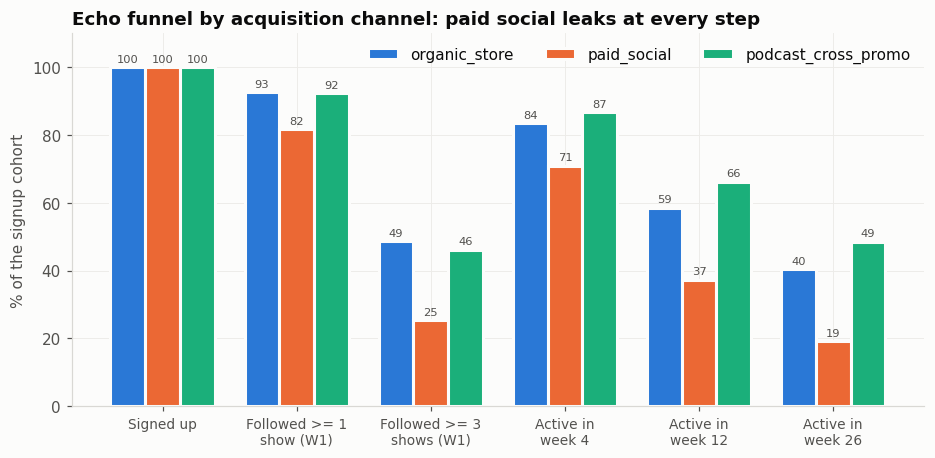

In [15]:
fig, ax = plt.subplots(figsize=(10, 4.4))
x = np.arange(len(funnel)); bw = 0.26
for i, ch in enumerate(CHANNELS):
    bars = ax.bar(x + (i - 1) * bw, funnel[ch] * 100, bw, color=CH_COLORS[ch], label=ch, edgecolor=SURFACE, linewidth=2)
    ax.bar_label(bars, fmt='%.0f', fontsize=7.5, color=INK2, padding=2)
ax.set_xticks(x, ['Signed up', 'Followed >= 1\nshow (W1)', 'Followed >= 3\nshows (W1)', 'Active in\nweek 4', 'Active in\nweek 12', 'Active in\nweek 26'], fontsize=9)
ax.set_ylabel('% of the signup cohort'); ax.set_ylim(0, 110)
ax.set_title('Echo funnel by acquisition channel: paid social leaks at every step')
ax.legend(ncol=3, loc='upper right')
save(fig, '03_funnel_by_channel'); plt.show()

### 3.2 The "aha moment": how many shows must a user follow in week 1?

,users,W4,W12
shows,,,
0,1832,72.500,40.000
1,3733,73.500,41.700
2,3862,75.200,43.900
3,2857,85.500,63.600
4,1619,86.800,65.000
5,817,85.900,64.700
6,306,92.200,72.200
7,166,85.500,66.900


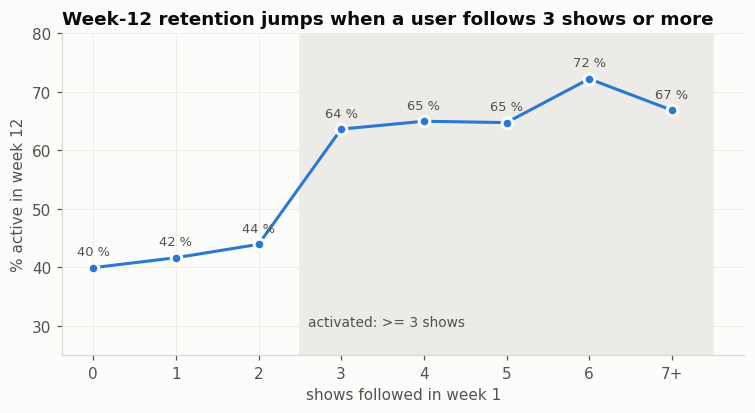

In [16]:
ret_by_shows = (STD[STD.max_age_obs >= 12]
                .assign(shows=lambda d: d.shows_followed_week1.clip(upper=7),
                        w4=lambda d: active_at(d.user_id, 4), w12=lambda d: active_at(d.user_id, 12))
                .groupby('shows').agg(users=('user_id', 'size'), W4=('w4', 'mean'), W12=('w12', 'mean')))
display(ret_by_shows.assign(W4=lambda d: (d.W4 * 100).round(1), W12=lambda d: (d.W12 * 100).round(1)))

fig, ax = plt.subplots(figsize=(8, 3.8))
ax.plot(ret_by_shows.index, ret_by_shows.W12 * 100, color=BLUE, marker='o', markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
for k, v in ret_by_shows.W12.items():
    ax.annotate(f'{v*100:.0f} %', (k, v * 100), xytext=(0, 8), textcoords='offset points', ha='center', fontsize=8.5, color=INK2)
ax.axvspan(2.5, 7.5, color='#ecebe8', zorder=0)
ax.text(2.6, 30, 'activated: >= 3 shows', fontsize=9, color=INK2)
ax.set_xticks(ret_by_shows.index, [str(i) if i < 7 else '7+' for i in ret_by_shows.index])
ax.set_xlabel('shows followed in week 1'); ax.set_ylabel('% active in week 12'); ax.set_ylim(25, 80)
ax.set_title('Week-12 retention jumps when a user follows 3 shows or more')
save(fig, '03_aha_moment'); plt.show()

The relationship is not linear: following 0, 1 or 2 shows gives about the same week-12 retention (~40-44 %), and **the step happens between 2 and 3 shows** (~64 %), after which it flattens. This is a textbook "aha moment": **activation = following at least 3 shows in week 1**.

In [17]:
act_share = STD.groupby('acquisition_channel').activated.mean()
print('Share of users activated (>= 3 shows in week 1):'); print(act_share.map(lambda x: f'{x:.1%}').to_string())
print(f'All channels: {STD.activated.mean():.1%}')

Share of users activated (>= 3 shows in week 1):
acquisition_channel
organic_store          48.1%
paid_social            25.1%
podcast_cross_promo    46.1%
All channels: 37.8%


### 3.3 Where is the value? (revenue concentration)

In [18]:
life_rev = w[w.user_id.isin(fc.user_id)].groupby('user_id').revenue.sum().reindex(fc.user_id).fillna(0).sort_values(ascending=False)
top20 = life_rev.iloc[:int(0.2 * len(life_rev))].sum() / life_rev.sum()
rev_w26 = life_rev[fc.set_index('user_id').w26].sum() / life_rev.sum()
print(f'Top 20 % of users generate {top20:.0%} of the ad revenue of the cohort')
print(f'Users still active in week 26 ({fc.w26.mean():.0%} of the cohort) generate {rev_w26:.0%} of its revenue')
print(f'Users not activated (< 3 shows) are {1 - fc.activated.mean():.0%} of signups but generate {life_rev[~fc.set_index("user_id").activated].sum() / life_rev.sum():.0%} of revenue')

Top 20 % of users generate 51% of the ad revenue of the cohort
Users still active in week 26 (33% of the cohort) generate 70% of its revenue
Users not activated (< 3 shows) are 62% of signups but generate 50% of revenue


### 3.4 The growth loop

Echo is a **retention-driven content loop**, financed by a (linear) paid funnel:

```
            ┌──────────────────────────────────────────────────────────────┐
            │                                                              │
  [Signup] ─► follows shows (W1) ─► new episodes ─► push "new episode" ─► session
     ▲                                                                      │
     │                                                                      ▼
     │        reinvest (paid_social)  ◄── ad revenue (€9 CPM) ◄── listening minutes ◄┘
     │                                                                      │
     └──── podcast cross-promo (shows promote Echo to their audience) ◄─────┘
```

* **Value** for the user = listening to the shows they follow. **Input** = followed shows; **output** = listening minutes, which produce ad revenue and keep the user in the loop.
* The push notification is the *trigger* of the loop. A *relevant* trigger ("new episode of a show you follow") feeds the loop; an *irrelevant* trigger ("Don't miss out!" five times a day) creates sessions without listening, and burns the trigger (users mute or leave). Section 7 tests this.
* The acquisition side is mostly a **funnel** (paid_social needs continuous spend) plus a weak acquisition loop through podcast cross-promotion. No invite data exists, so the K-factor cannot be measured.

**Where value leaks:**
1. **Activation**: only 38 % of users follow 3+ shows in week 1 (25 % on paid_social). Users who never reach it are 62 % of signups but bring only half of the revenue, and the top 20 % of users bring 51 % of it.
2. **Early retention (weeks 1-8)**, especially for paid_social.
3. **Paid social** brings the most users but the least valuable ones (section 5).

## 4. Segments: do the differences survive when we compare like with like?

### 4.1 Retention curves by channel (normal push experience)

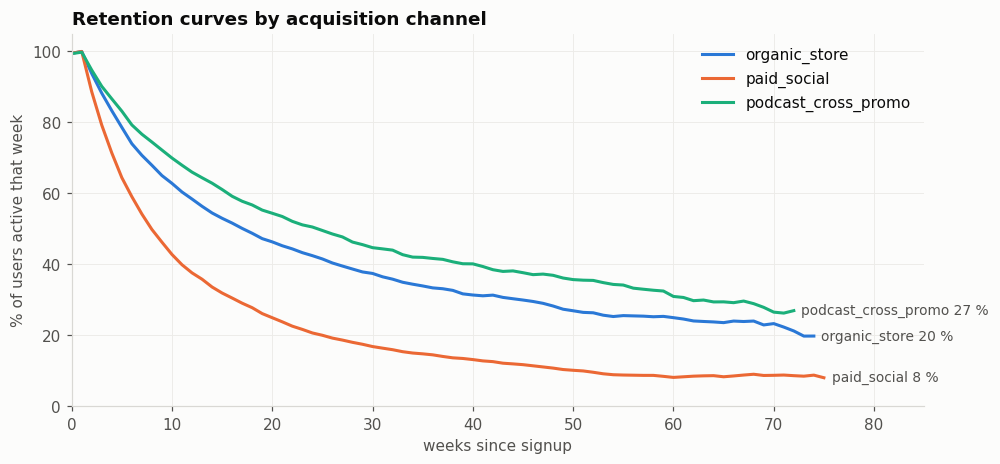

In [19]:
vc_ch = {ch: value_curves(STD[STD.acquisition_channel == ch], min_n=200) for ch in CHANNELS}
fig, ax = plt.subplots(figsize=(10, 4.4))
for ch, vc in vc_ch.items():
    ax.plot(vc.index, vc.S * 100, color=CH_COLORS[ch], label=ch)
    end_label(ax, vc.index[-1], vc.S.iloc[-1] * 100, f'{ch} {vc.S.iloc[-1]*100:.0f} %')
ax.set_xlabel('weeks since signup'); ax.set_ylabel('% of users active that week'); ax.set_ylim(0, 105)
ax.set_xlim(0, 85)
ax.set_title('Retention curves by acquisition channel')
ax.legend(loc='upper right')
save(fig, '04_retention_by_channel'); plt.show()

In [20]:
def seg_table(df, col, ks=(4, 8, 12, 26)):
    out = {}
    for k in ks:
        obs = df[df.max_age_obs >= k]
        out[f'W{k}'] = active_at(obs.user_id, k).groupby(obs[col].values).mean()
    t = pd.DataFrame(out)
    t.insert(0, 'users', df.groupby(col).size())
    t.insert(1, '% activated', df.groupby(col).activated.mean())
    return t

for col in ['acquisition_channel', 'platform', 'age_bucket', 'activated']:
    t = seg_table(STD, col)
    display((t.drop(columns='users') * 100).round(1).assign(users=t.users))

,% activated,W4,W8,W12,W26,users
organic_store,48.100,83.300,67.900,58.400,40.300,7170
paid_social,25.100,71.400,49.800,37.600,19.200,8349
podcast_cross_promo,46.100,86.600,74.400,65.900,48.500,3923


,% activated,W4,W8,W12,W26,users
Android,38.400,79.000,61.500,51.100,32.700,9783
iOS,37.200,78.600,61.200,50.500,32.500,9659


,% activated,W4,W8,W12,W26,users
18-24,31.900,75.100,55.500,44.200,25.500,5568
25-34,38.400,80.000,63.400,53.100,34.900,6522
35-44,42.200,81.500,64.300,55.100,37.100,3874
45+,42.800,80.200,64.400,53.000,35.300,2865


,% activated,W4,W8,W12,W26,users
False,0.000,74.100,53.900,42.300,23.000,12090
True,100.000,86.500,73.600,64.700,48.300,7352


Raw view: paid_social retains far worse (W12 ≈ 38 % vs 58-66 %), platforms are identical, 18-24 year-olds retain ~9 pp worse, and activation is the strongest split of all (W12 65 % vs 42 %).

**But paid_social users also follow fewer shows in week 1** (25 % activated vs 46-48 % for the other channels). Is the paid_social gap just a *mix effect* of activation? We compare like with like.

Week-8 retention by channel WITHIN each "shows followed" level (%):


acquisition_channel,organic_store,paid_social,podcast_cross_promo
shows,,,
0,59.600,43.500,72.300
1,57.600,46.000,69.600
2,61.800,45.600,68.300
3,75.900,64.100,79.400
4,78.500,63.100,81.400
5,75.500,59.200,80.700


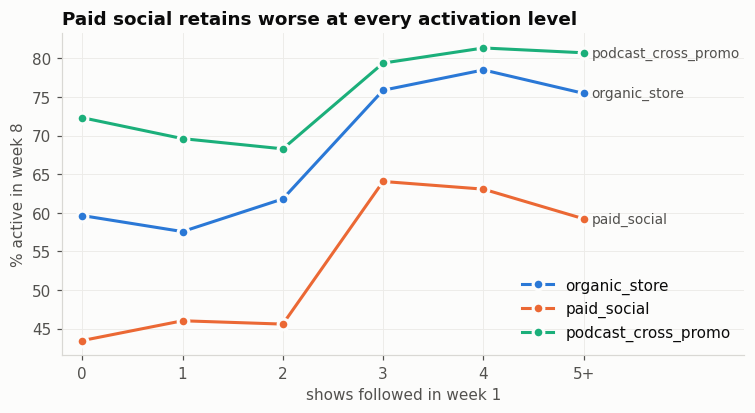

,raw W8,W8 standardised to the same shows mix,"gap vs organic (raw, pp)","gap vs organic (standardised, pp)"
acquisition_channel,,,,
organic_store,67.900,66.100,0.000,0.000
paid_social,49.800,51.900,-18.100,-14.200
podcast_cross_promo,74.400,73.600,6.500,7.600


In [21]:
like = STD[STD.max_age_obs >= 8].assign(w8=lambda d: active_at(d.user_id, 8), shows=lambda d: d.shows_followed_week1.clip(upper=5))
strat = like.pivot_table(index='shows', columns='acquisition_channel', values='w8', aggfunc='mean')
nstrat = like.pivot_table(index='shows', columns='acquisition_channel', values='w8', aggfunc='size')
print('Week-8 retention by channel WITHIN each "shows followed" level (%):')
display((strat * 100).round(1))

fig, ax = plt.subplots(figsize=(8, 3.8))
for ch in CHANNELS:
    ax.plot(strat.index, strat[ch] * 100, color=CH_COLORS[ch], marker='o', markersize=7, markeredgecolor=SURFACE, markeredgewidth=2, label=ch)
    end_label(ax, strat.index[-1], strat[ch].iloc[-1] * 100, ch)
ax.set_xticks(strat.index, ['0', '1', '2', '3', '4', '5+'])
ax.set_xlabel('shows followed in week 1'); ax.set_ylabel('% active in week 8'); ax.set_xlim(-0.2, 6.6)
ax.set_title('Paid social retains worse at every activation level')
ax.legend(loc='lower right')
save(fig, '04_like_with_like'); plt.show()

# direct standardisation: give every channel the same "shows followed" mix (the overall one)
mix = like.shows.value_counts(normalize=True).sort_index()
std_ret = (strat.mul(mix, axis=0)).sum()
raw_ret = like.groupby('acquisition_channel').w8.mean()
comp = pd.DataFrame({'raw W8': raw_ret, 'W8 standardised to the same shows mix': std_ret}) * 100
comp['gap vs organic (raw, pp)'] = comp['raw W8'] - comp.loc['organic_store', 'raw W8']
comp['gap vs organic (standardised, pp)'] = comp['W8 standardised to the same shows mix'] - comp.loc['organic_store', 'W8 standardised to the same shows mix']
display(comp.round(1))

In [22]:
# Linear probability model: active in week 8 ~ channel + activation + shows + platform + age  (OLS with dummies)
X = pd.get_dummies(like[['acquisition_channel', 'platform', 'age_bucket']], drop_first=True).astype(float)
X['activated'] = like.activated.astype(float)
X['shows_followed_week1'] = like.shows_followed_week1.astype(float)
X.insert(0, 'const', 1.0)
y = like.w8.astype(float).values
beta, *_ = np.linalg.lstsq(X.values, y, rcond=None)
resid = y - X.values @ beta
sigma2 = resid @ resid / (len(y) - X.shape[1])
se = np.sqrt(np.diag(sigma2 * np.linalg.inv(X.values.T @ X.values)))
ols = pd.DataFrame({'effect on P(active W8), pp': beta * 100, 'std err, pp': se * 100, 't': beta / se}, index=X.columns)
display(ols.round(2))

,"effect on P(active W8), pp","std err, pp",t
const,60.260,1.210,49.760
acquisition_channel_paid_social,-14.630,0.900,-16.190
acquisition_channel_podcast_cross_promo,6.840,1.020,6.730
platform_iOS,-0.250,0.730,-0.340
age_bucket_25-34,0.750,0.940,0.800
age_bucket_35-44,-0.760,1.100,-0.690
age_bucket_45+,-1.410,1.220,-1.160
activated,15.320,1.320,11.620
shows_followed_week1,0.220,0.420,0.520


**Conclusion of section 4.**

* The paid_social gap is **partly a mix effect** (paid users follow fewer shows), but **most of it survives** once we compare like with like: standardising the shows mix shrinks the week-8 gap with organic only from −18 pp to −14 pp, and the regression gives −14.6 pp (t = −16) at equal activation, platform and age. Paid social brings intrinsically less engaged users.
* Podcast cross-promo users are the best, +7 pp vs organic at equal activation.
* **The age difference does not survive**: 18-24 year-olds retain worse only because they follow fewer shows; at equal activation, age has no significant effect (|t| < 1.4). Platform has no effect at all.
* Activation (3+ shows) is the biggest lever we can act on: +15 pp of week-8 retention on top of the channel effect.

## 5. Unit economics: CAC, retention, LTV, payback

### 5.1 Revenue per active user

In [23]:
act_rows = w[w.push_variant != 'aggressive_push']
arpu_w = act_rows.groupby('acquisition_channel').agg(ads_per_active_week=('ad_impressions', 'mean'),
                                                     minutes_per_active_week=('minutes', 'mean'),
                                                     revenue_per_active_week=('revenue', 'mean'))
arpu_w.loc['all'] = [act_rows.ad_impressions.mean(), act_rows.minutes.mean(), act_rows.revenue.mean()]
arpu_w['revenue_per_active_month (x 4.33)'] = arpu_w.revenue_per_active_week * 52 / 12
display(arpu_w.round(3))
print(f'Ads per listening hour: {ADS_PER_HOUR:.2f} -> 1 listening hour = EUR {ADS_PER_HOUR * REV_PER_AD:.3f}')

,ads_per_active_week,minutes_per_active_week,revenue_per_active_week,revenue_per_active_month (x 4.33)
acquisition_channel,,,,
organic_store,11.474,81.182,0.103,0.448
paid_social,11.599,82.031,0.104,0.452
podcast_cross_promo,11.455,80.979,0.103,0.447
all,11.510,81.409,0.104,0.449


Ads per listening hour: 8.57 -> 1 listening hour = EUR 0.077


An active user is worth about **€0.10 per week (≈ €0.45 per month)**. Intensity per active week is almost identical across channels, so **differences in LTV come almost entirely from retention**.

### 5.2 CAC

In [24]:
signups_m = u.groupby(['signup_month', 'acquisition_channel']).size().unstack()
ue = spend.set_index('month')[['spend_eur', 'spend_imputed']].join(signups_m)
ue['total_signups'] = signups_m.sum(axis=1)
ue['CAC paid_social'] = ue.spend_eur / ue.paid_social
ue['blended CAC (all signups)'] = ue.spend_eur / ue.total_signups
display(ue.round(2))
CAC_PAID = ue['CAC paid_social'].median()
print(f'CAC paid_social: EUR {CAC_PAID:.2f} (min {ue["CAC paid_social"].min():.2f}, max {ue["CAC paid_social"].max():.2f}) | blended CAC: EUR {ue["blended CAC (all signups)"].median():.2f}')

,spend_eur,spend_imputed,organic_store,paid_social,podcast_cross_promo,total_signups,CAC paid_social,blended CAC (all signups)
month,,,,,,,,
2025-01-01,990.000,990.000,300,380,150,830,2.610,1.190
2025-02-01,"1,020.000","1,020.000",312,391,157,860,2.610,1.190
2025-03-01,"1,050.000","1,050.000",324,403,165,892,2.610,1.180
2025-04-01,"1,080.000","1,080.000",337,415,173,925,2.600,1.170
2025-05-01,NaN,"1,296.470",350,427,182,959,NaN,NaN
2025-06-01,"1,150.000","1,150.000",364,440,191,995,2.610,1.160
2025-07-01,"1,180.000","1,180.000",379,453,201,1033,2.600,1.140
2025-08-01,"1,220.000","1,220.000",394,467,211,1072,2.610,1.140
2025-09-01,"1,250.000","1,250.000",410,481,221,1112,2.600,1.120


CAC paid_social: EUR 2.61 (min 2.60, max 2.61) | blended CAC: EUR 1.12


CAC is **flat at €2.61** over 18 months although spend grew by +65 %: paid_social has **not yet reached its saturation point** (course: paid channel dynamics). Every extra euro still buys the same number of users. The question is whether those users are worth €2.61.

### 5.3 LTV, LTV:CAC and payback by channel

In [25]:
ext_ch = {ch: extend(vc_ch[ch]) for ch in CHANNELS}
rows = {}
for ch in CHANNELS:
    e = ext_ch[ch]; cum = e.v.cumsum()
    cac = CAC_PAID if ch == 'paid_social' else 0.0
    payback = int((cum >= cac).idxmax()) if (cum >= cac).any() and cac > 0 else None
    rows[ch] = {
        'observed weeks': int(e.observed.sum()),
        'revenue per user, first 12 weeks': cum[11],
        'LTV 52 weeks': cum[51], 'LTV 104 weeks': cum[103],
        'share of LTV104 extrapolated': e.v[~e.observed].iloc[:104 - e.observed.sum()].sum() / cum[103] if e.observed.sum() < 104 else 0,
        'CAC': cac,
        'LTV104 : CAC': cum[103] / cac if cac else np.nan,
        'payback (weeks)': payback if payback is not None else ('> 160' if cac else 'n/a (no spend)'),
    }
ltv = pd.DataFrame(rows).T
display(ltv)

,observed weeks,"revenue per user, first 12 weeks",LTV 52 weeks,LTV 104 weeks,share of LTV104 extrapolated,CAC,LTV104 : CAC,payback (weeks)
organic_store,75,0.989,2.546,3.648,0.149,0.000,NaN,n/a (no spend)
paid_social,76,0.839,1.603,2.032,0.108,2.605,0.780,> 160
podcast_cross_promo,73,1.038,2.925,4.260,0.159,0.000,NaN,n/a (no spend)


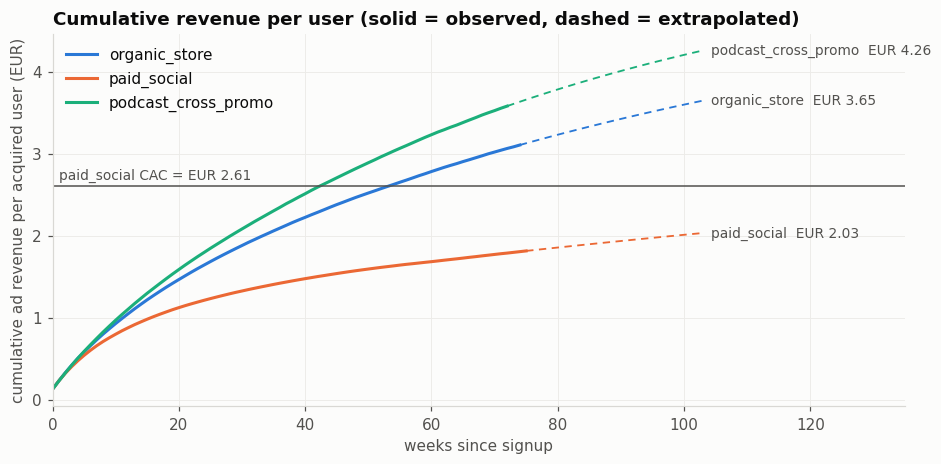

In [26]:
fig, ax = plt.subplots(figsize=(10, 4.4))
for ch in CHANNELS:
    e = ext_ch[ch]; cum = e.v.cumsum().iloc[:104]
    K = int(e.observed.iloc[:104].sum()) - 1
    ax.plot(cum.index[:K + 1], cum.iloc[:K + 1], color=CH_COLORS[ch], label=ch)
    ax.plot(cum.index[K:], cum.iloc[K:], color=CH_COLORS[ch], linewidth=1.2, linestyle=(0, (4, 3)))
    end_label(ax, 103, cum.iloc[-1], f'{ch}  EUR {cum.iloc[-1]:.2f}')
ax.axhline(CAC_PAID, color=INK2, linewidth=1)
ax.text(1, CAC_PAID + 0.08, f'paid_social CAC = EUR {CAC_PAID:.2f}', fontsize=9, color=INK2)
ax.set_xlim(0, 135); ax.set_xlabel('weeks since signup'); ax.set_ylabel('cumulative ad revenue per acquired user (EUR)')
ax.set_title('Cumulative revenue per user (solid = observed, dashed = extrapolated)')
ax.legend(loc='upper left')
save(fig, '05_ltv_curves'); plt.show()

**Paid social does not pay back.** A paid user generates about **€1.60 in 52 weeks and €2.04 in two years**, against a CAC of **€2.61**: **LTV:CAC ≈ 0.78 < 1**, so Echo *loses money on every paid user* even before any operating cost (the course threshold for a healthy business is LTV ≥ 3 × CAC). Organic (€3.65) and cross-promo (€4.26) users are worth about twice as much over two years and cost nothing in media. About 85-90 % of these LTVs are observed, not extrapolated.

*Caveats:* (1) LTV is gross ad revenue, a real gross margin (hosting, content rights, ad-tech fees) would make paid_social even worse; (2) we ignore any indirect value of paid users (word of mouth, ranking in the store) for which there is no data; (3) the tail after the observed horizon is extrapolated.

### 5.4 Unit economics by cohort (like with like: same 12-week horizon)

In [27]:
coh = STD[STD.max_age_obs >= 11].copy()
rev12 = w[(w.age_wk <= 11) & w.user_id.isin(coh.user_id)].groupby('user_id').revenue.sum()
coh['rev12'] = coh.user_id.map(rev12).fillna(0)
coh['w12'] = active_at(coh.user_id, 11)
coh['quarter'] = coh.signup_date.dt.to_period('Q').astype(str)
cq = coh.pivot_table(index='quarter', columns='acquisition_channel', values='rev12', aggfunc='mean')
print('12-week revenue per acquired user (EUR), by signup quarter and channel:')
display(cq.round(3))
print('12-week payback ratio of paid_social (12-week revenue / CAC):')
display((cq.paid_social / CAC_PAID).round(2).to_frame('rev12 / CAC'))

12-week revenue per acquired user (EUR), by signup quarter and channel:


acquisition_channel,organic_store,paid_social,podcast_cross_promo
quarter,,,
2025Q1,1.012,0.853,1.050
2025Q2,0.972,0.832,1.022
2025Q3,0.987,0.833,1.035
2025Q4,1.005,0.827,1.050
2026Q1,0.975,0.860,1.037
2026Q2,0.998,0.837,1.039


12-week payback ratio of paid_social (12-week revenue / CAC):


,rev12 / CAC
quarter,
2025Q1,0.330
2025Q2,0.320
2025Q3,0.320
2025Q4,0.320
2026Q1,0.330
2026Q2,0.320


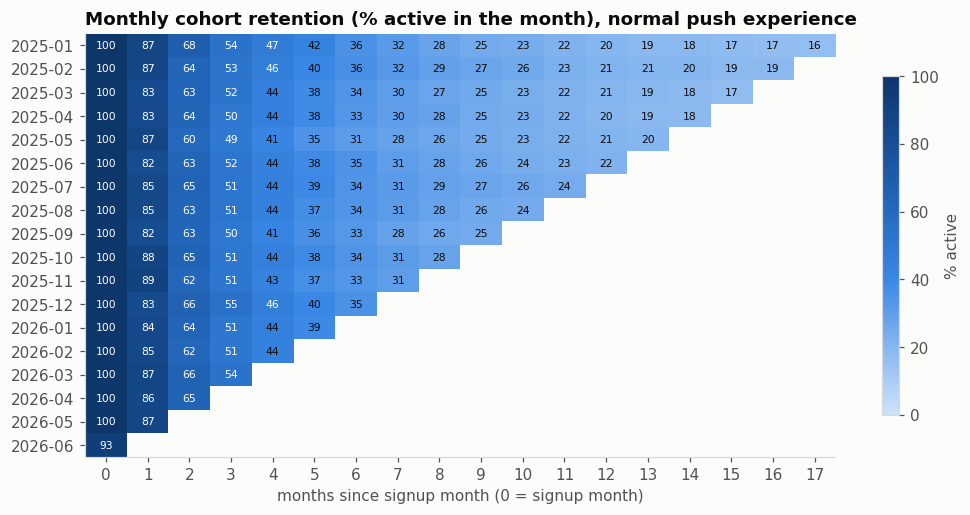

In [28]:
# classic cohort triangle (course slide "cohort analysis"): % of a monthly cohort active in calendar month m+k
um = w[['user_id', 'week_start']].assign(month=lambda d: d.week_start.dt.to_period('M')).drop_duplicates(['user_id', 'month'])
um = um.merge(u[['user_id', 'signup_month']].assign(cm=lambda d: d.signup_month.dt.to_period('M')), on='user_id')
um['k'] = (um.month - um.cm).apply(lambda x: x.n)
um = um[um.k >= 0]   # the signup week can start in the previous calendar month: not a "month -1" of life
size = STD.groupby(STD.signup_month.dt.to_period('M')).size()
tri = um[um.user_id.isin(STD.user_id)].groupby(['cm', 'k']).user_id.nunique().unstack()
tri = tri.div(size, axis=0)
tri = tri.loc[:, 0:17]
fig, ax = plt.subplots(figsize=(11, 5))
im = ax.imshow(tri.values * 100, cmap=SEQ, vmin=0, vmax=100, aspect='auto')
for i in range(tri.shape[0]):
    for j in range(tri.shape[1]):
        val = tri.values[i, j]
        if not np.isnan(val):
            ax.text(j, i, f'{val*100:.0f}', ha='center', va='center', fontsize=7, color='white' if val > 0.45 else INK)
ax.set_xticks(range(tri.shape[1]), tri.columns); ax.set_yticks(range(tri.shape[0]), [str(p) for p in tri.index])
ax.set_xlabel('months since signup month (0 = signup month)'); ax.set_title('Monthly cohort retention (% active in the month), normal push experience')
ax.grid(False); fig.colorbar(im, ax=ax, label='% active', shrink=0.8)
save(fig, '05_cohort_triangle'); plt.show()

Paid social recovers only **a third of its CAC in the first 12 weeks**, in every quarter. The cohort triangle is **remarkably stable**: every monthly cohort since January 2025 has the same shape (~85 % active in the month after signup, ~64 % in month 2, ~51 % in month 3, ~44 % in month 4, ~25 % after 9 months). There is no sign that the product got better or worse over 18 months for users with normal notifications, and paid_social cohort value does not degrade as spend grows. The latest cell of each row is slightly understated because June 2026 is only observed until the 28th.

## 6. What changed during these 18 months?

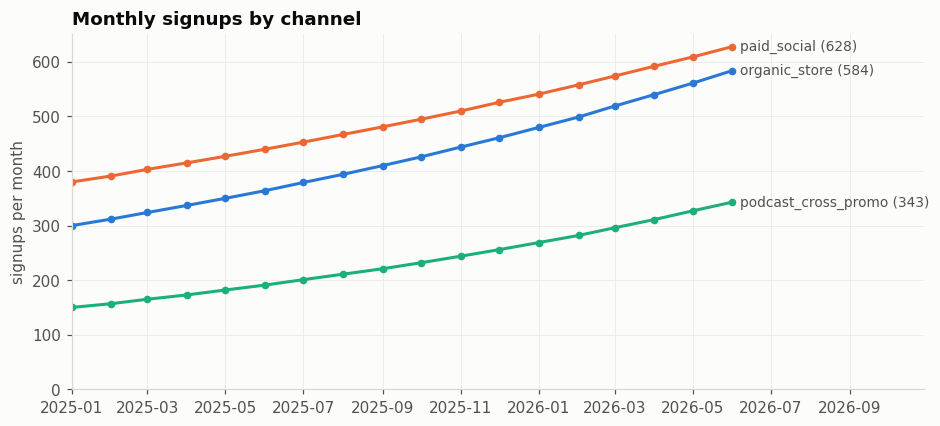

Compound monthly growth rate (log-linear fit): {'organic_store': '4.00%', 'paid_social': '3.00%', 'podcast_cross_promo': '5.00%', 'paid spend': '2.84%'}
Channel mix first vs last month: {'organic_store': 0.361, 'paid_social': 0.458, 'podcast_cross_promo': 0.181} -> {'organic_store': 0.376, 'paid_social': 0.404, 'podcast_cross_promo': 0.221}


In [29]:
fig, ax = plt.subplots(figsize=(10, 4.2))
for ch in CHANNELS:
    ax.plot(signups_m.index, signups_m[ch], color=CH_COLORS[ch], marker='o', markersize=4)
    end_label(ax, signups_m.index[-1], signups_m[ch].iloc[-1], f'{ch} ({signups_m[ch].iloc[-1]:,})')
ax.set_xlim(signups_m.index[0], signups_m.index[-1] + pd.Timedelta(days=150))
ax.set_ylabel('signups per month'); ax.set_ylim(0)
ax.set_title('Monthly signups by channel')
save(fig, '06_signups_by_channel'); plt.show()

months_n = np.arange(len(signups_m))
growth = {ch: np.exp(np.polyfit(months_n, np.log(signups_m[ch]), 1)[0]) - 1 for ch in CHANNELS}
growth['paid spend'] = np.exp(np.polyfit(months_n, np.log(ue.spend_imputed), 1)[0]) - 1
print('Compound monthly growth rate (log-linear fit):', {k: f'{v:.2%}' for k, v in growth.items()})
print('Channel mix first vs last month:', (signups_m.iloc[0] / signups_m.iloc[0].sum()).round(3).to_dict(), '->', (signups_m.iloc[-1] / signups_m.iloc[-1].sum()).round(3).to_dict())

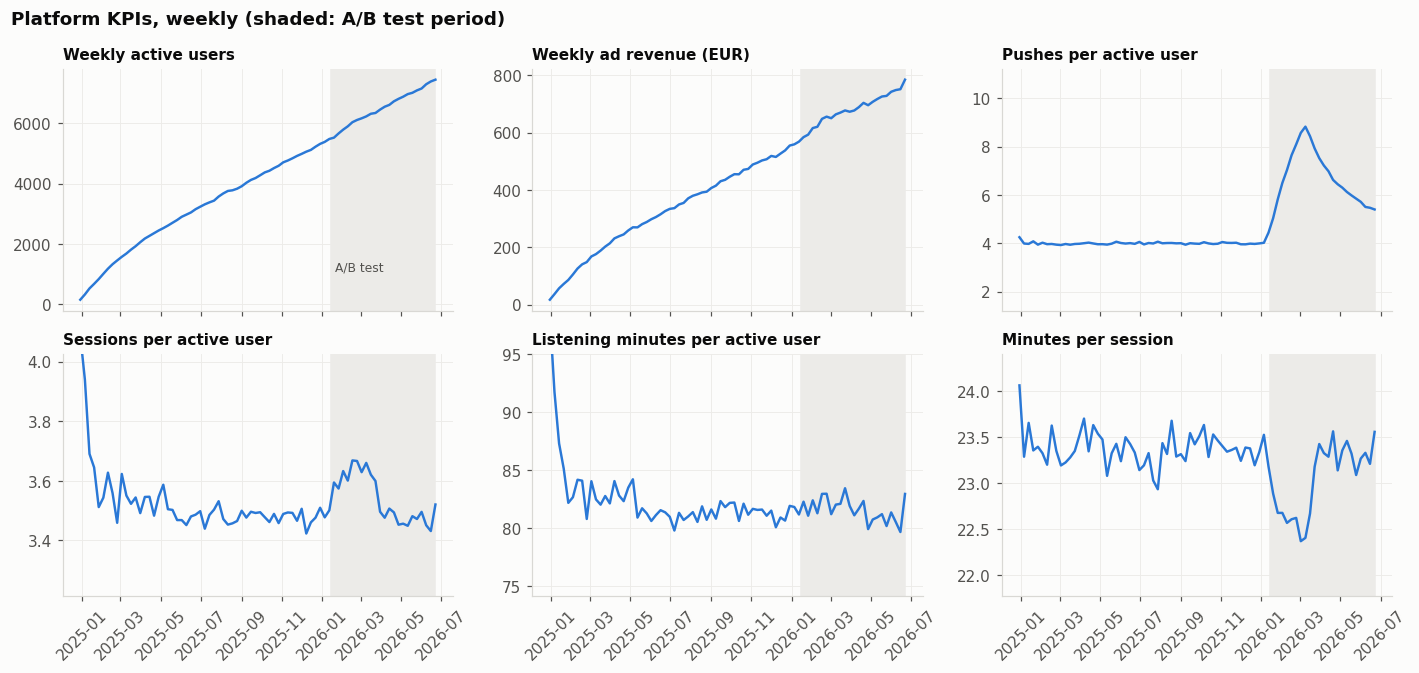

,WAU,sessions per WAU,minutes per WAU,pushes per WAU,minutes per session
week_start,,,,,
2025-12-01,4989,3.510,81.480,3.960,23.240
2025-12-08,5062,3.420,80.040,3.950,23.390
2025-12-15,5121,3.460,80.890,3.980,23.380
2025-12-22,5227,3.480,80.620,3.970,23.190
2025-12-29,5321,3.510,81.890,3.990,23.330
2026-01-05,5387,3.480,81.790,4.020,23.520
2026-01-12,5485,3.500,81.140,4.440,23.180
2026-01-19,5528,3.590,82.250,5.030,22.890
2026-01-26,5668,3.570,81.040,5.810,22.680


In [30]:
kpi = w.groupby('week_start').agg(WAU=('user_id', 'nunique'), sessions=('sessions', 'sum'), minutes=('minutes', 'sum'),
                                   ads=('ad_impressions', 'sum'), push=('push_notifications_received', 'sum'), revenue=('revenue', 'sum'))
kpi['sessions per WAU'] = kpi.sessions / kpi.WAU
kpi['minutes per WAU'] = kpi.minutes / kpi.WAU
kpi['pushes per WAU'] = kpi.push / kpi.WAU
kpi['minutes per session'] = kpi.minutes / kpi.sessions
kpi['listening hours'] = kpi.minutes / 60

panels = [('WAU', 'Weekly active users'), ('revenue', 'Weekly ad revenue (EUR)'), ('pushes per WAU', 'Pushes per active user'),
          ('sessions per WAU', 'Sessions per active user'), ('minutes per WAU', 'Listening minutes per active user'), ('minutes per session', 'Minutes per session')]
fig, axes = plt.subplots(2, 3, figsize=(13, 6.2), sharex=True)
for ax, (col, title) in zip(axes.flat, panels):
    ax.axvspan(TEST_START, LAST_FULL_WEEK, color='#ecebe8', zorder=0)
    ax.plot(kpi.index, kpi[col], color=BLUE, linewidth=1.6)
    ax.set_title(title, fontsize=10)
    if col not in ('WAU', 'revenue'):
        lo, hi = kpi[col].quantile(.02), kpi[col].quantile(.98); pad = (hi - lo) * 0.6
        ax.set_ylim(lo - pad, hi + pad)
for ax in axes[1]:
    ax.tick_params(axis='x', rotation=45)
axes[0, 0].text(TEST_START + pd.Timedelta(days=5), kpi.WAU.max() * 0.15, 'A/B test', fontsize=8, color=INK2)
fig.suptitle('Platform KPIs, weekly (shaded: A/B test period)', x=0.01, ha='left', fontweight='bold')
fig.tight_layout()
save(fig, '06_platform_kpis'); plt.show()
display(kpi.loc['2025-12-01':'2026-04-30', ['WAU', 'sessions per WAU', 'minutes per WAU', 'pushes per WAU', 'minutes per session']].round(2))

**What changed during the 18 months?**

Signups grew on every channel. With an exponential fit ($y = a \cdot b^x$ model), organic signups grow by about 4 % per month, paid social by 3 % and podcast cross-promo by 5 %. Because of this, the number of weekly active users went from about 5,000 in December 2025 to about 7,500 in June 2026, and the ad revenue grew at the same pace. The usage per active user (sessions and minutes) stayed almost the same, so the growth comes from having more users, not from users listening more.

The paid social budget also increased, from €990 to €1,630 per month (about +3 % per month). Paid signups grew in the same proportion, so the CAC stayed around €2.6 during the whole period: we don't reach the saturation point for now (saturation is reached when investing more in paid social no longer brings new users). But as shown in part 5, a paid user still brings less money than what it costs.

The channel mix changed a little: paid social went from 46 % to 40 % of the signups, and podcast cross-promo from 18 % to 22 %. This is a good thing for Echo because these users cost nothing and stay longer.

The biggest change is the A/B test that started on 15 January 2026. The number of pushes per active user went from about 4 to almost 9 per week. Sessions per active user went up a little (about +5 %), but the listening minutes per active user did not change. So users open the app more often, but they don't listen more and Echo doesn't earn more from ads. This also raise the question question of using openened sessions as a success metric for the study. With this result we can see that more session doesn't mean more ad revenue. We will dive a little deeper in this question in part 7. 

## 7. The A/B test: aggressive push vs control

Context: New users who signed up between 15 Jan and 15 Mar 2026 were randomly split: *control* (normal notifications) vs *aggressive_push* (≈5 notifications a day, "Don't miss out!" copy). The growth team's claim: *"sessions are up 30 %"*.

### 7.1 Is the experiment valid? (sample ratio mismatch and balance)

We will start by making sure that the experiment is valid. We will do a chi2 test to see if there is an even repartition (50-50) and for each variable we will do an independancy test of chi2.

In [31]:
ut = u[u.push_variant.isin(['control', 'aggressive_push'])].copy()
H = int(ut.max_age_obs.min())          # every test user is observable for weeks 0..H
n_arm = ut.push_variant.value_counts()
srm_p = stats.chisquare(n_arm.values).pvalue
print(f'Arms: {n_arm.to_dict()} | SRM chi-square p = {srm_p:.2f} -> {"OK" if srm_p > 0.01 else "PROBLEM"}')
print(f'All test users are observable for weeks 0..{H} of their life (up to {int(ut.max_age_obs.max())} for the earliest).')
bal = []
for col in ['acquisition_channel', 'platform', 'age_bucket', 'activated']:
    ct = pd.crosstab(ut[col], ut.push_variant)
    bal.append({'covariate': col, 'chi2 p-value': stats.chi2_contingency(ct)[1]})
bal.append({'covariate': 'shows_followed_week1 (t-test)', 'chi2 p-value': stats.ttest_ind(*[g.shows_followed_week1 for _, g in ut.groupby('push_variant')]).pvalue})
display(pd.DataFrame(bal).round(3))
pushes = w[w.user_id.isin(ut.user_id)].groupby('push_variant').push_notifications_received.mean()
print('Pushes per active week:', pushes.round(1).to_dict())

Arms: {'control': 1366, 'aggressive_push': 1343} | SRM chi-square p = 0.66 -> OK
All test users are observable for weeks 0..15 of their life (up to 23 for the earliest).


,covariate,chi2 p-value
0,acquisition_channel,0.630
1,platform,0.627
2,age_bucket,0.166
3,activated,0.091
4,shows_followed_week1 (t-test),0.511


Pushes per active week: {'aggressive_push': 32.0, 'control': 4.0}


No sample-ratio mismatch and the arms are balanced on channel, platform, age and activation beacuase all p value are upper than 0.05 and the treatment was really delivered: "~32 pushes per week vs 4".

### 7.2 Reproducing the "+30 % sessions" claim, and looking beyond it

We will firstly explain the statement made by the team by analysing the dataframe in the same scope as they did. 
We can suppose that the interval of analysis 15 january- 15 march can biase the study because new users might come more regularly at the beginning but quit the app if they receive pushier notifications. Therefore they can allegedly cause misleading results if they started there sessions in march for example.
We will then compute an additional result more fair/relevant, by only reviewing users whom we have enough informations to analyse in a given period (16 weeks).

In [32]:
def per_user(frame, users):
    g = frame.groupby('user_id').agg(active_weeks=('week_start', 'count'), sessions=('sessions', 'sum'), minutes=('minutes', 'sum'),
                                     ad_impressions=('ad_impressions', 'sum'), revenue=('revenue', 'sum'), pushes=('push_notifications_received', 'sum'))
    g = g.reindex(users.user_id).fillna(0)
    g['push_variant'] = users.set_index('user_id').push_variant
    return g


def lift_table(pu, metrics):
    rows = {}
    for m in metrics:
        c = pu.loc[pu.push_variant == 'control', m]; a = pu.loc[pu.push_variant == 'aggressive_push', m]
        rows[m] = {'control': c.mean(), 'aggressive_push': a.mean(), 'lift': a.mean() / c.mean() - 1,
                   'p-value (Welch)': stats.ttest_ind(a, c, equal_var=False).pvalue}
    t = pd.DataFrame(rows).T
    return t


per_user creates a summary by users according to the type of notifications
lift_table computes different metrics related to the activity of users in a table

In [33]:

T = w[w.user_id.isin(ut.user_id)]
claim = per_user(T[T.week_start <= pd.Timestamp('2026-03-09')], ut)       # calendar weeks of the test window
print('A) What the growth team saw: per user, during the test window (15 Jan - 15 Mar 2026)')
display(lift_table(claim, ['sessions', 'minutes', 'revenue']).style.format({'control': '{:.2f}', 'aggressive_push': '{:.2f}', 'lift': '{:+.1%}', 'p-value (Welch)': '{:.3g}'}))

full = per_user(T[T.age_wk <= H], ut)
full['minutes per session'] = full.minutes / full.sessions
print(f'B) The full picture: per acquired user over their first {H + 1} weeks of life (all users fully observed)')
display(lift_table(full, ['sessions', 'active_weeks', 'minutes', 'ad_impressions', 'revenue', 'pushes']).style.format({'control': '{:.2f}', 'aggressive_push': '{:.2f}', 'lift': '{:+.1%}', 'p-value (Welch)': '{:.3g}'}))
tot = T.groupby('push_variant')[['minutes', 'sessions', 'ad_impressions']].sum()
mps = tot.minutes / tot.sessions
aph = tot.ad_impressions / tot.minutes * 60


A) What the growth team saw: per user, during the test window (15 Jan - 15 Mar 2026)


,control,aggressive_push,lift,p-value (Welch)
sessions,15.49,20.71,+33.7%,5.51e-44
minutes,364.04,371.59,+2.1%,0.363
revenue,0.46,0.54,+16.6%,9.07e-13


B) The full picture: per acquired user over their first 16 weeks of life (all users fully observed)


,control,aggressive_push,lift,p-value (Welch)
sessions,38.20,41.40,+8.4%,2.01e-05
active_weeks,10.86,9.81,-9.7%,3.56e-07
minutes,897.01,832.17,-7.2%,0.000251
ad_impressions,126.66,126.58,-0.1%,0.974
revenue,1.14,1.14,-0.1%,0.974
pushes,43.78,313.84,+616.8%,0


We can confirm our hypothesis : the claim is true but misleading.

Indeed the short-term view shows some tempting stats:
During the test window, aggressive users had +34 % sessions and even +17 % ad revenue, with the same listening time. 

But over the first 16 weeks of life the benefit of the agressive push becomes slightly less significant: aggressive users are active −10 % fewer weeks, listen −7 % less, and generate the same revenue. 
The early gain has already been eaten by churn, and the gap keeps growing.
Besides, we can suppose that this tendancy will become more and more remarkable by the time.

Sessions are at the opposite of the idea of sustainable and long-term growth of the North Star Metric seen in the course, vanity metric: pushes inflate app opens without creating listening, which is the value users come for.

### 7.3 Retention: the hidden cost

Let's push further our hypothesis : are pushy notifications providing a short-term activity of users at the expense of his long term commitment ?
So to say, we will analyze the churn (and thus the retention) according to the type of notifications

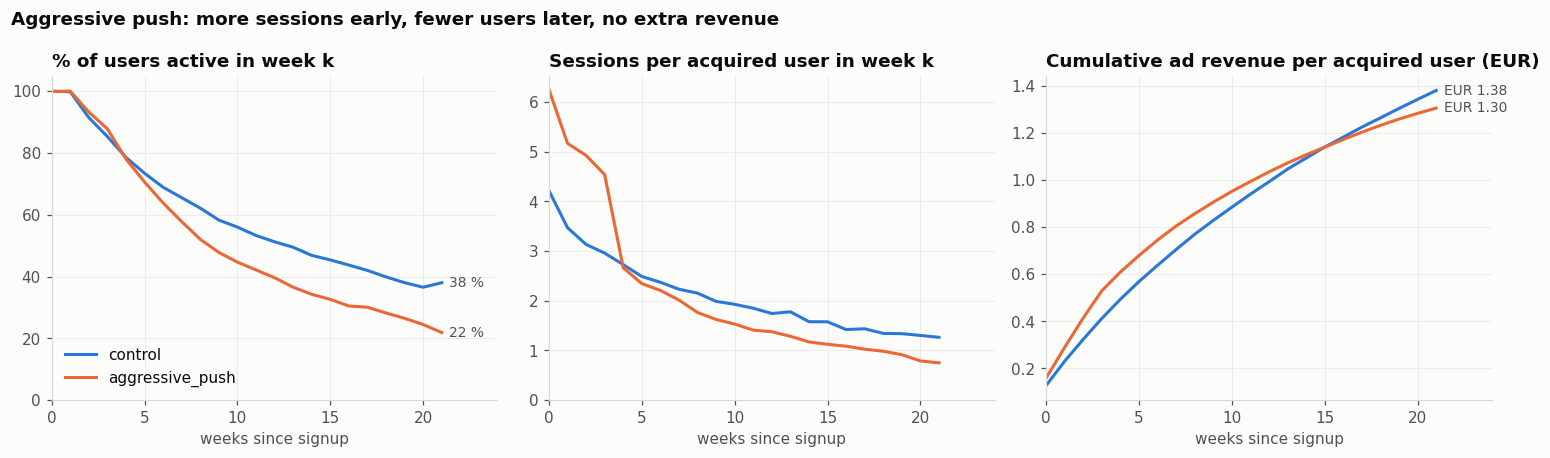

In [34]:
vc_ab = {arm: value_curves(ut[ut.push_variant == arm], min_n=300) for arm in ['control', 'aggressive_push']}
fig, axes = plt.subplots(1, 3, figsize=(14, 4.2))
for arm, vc in vc_ab.items():
    axes[0].plot(vc.index, vc.S * 100, color=AB_COLORS[arm], label=arm)
    axes[1].plot(vc.index, vc.sess_per_user, color=AB_COLORS[arm], label=arm)
    axes[2].plot(vc.index, vc.v.cumsum(), color=AB_COLORS[arm], label=arm)
    end_label(axes[0], vc.index[-1], vc.S.iloc[-1] * 100, f'{vc.S.iloc[-1]*100:.0f} %')
    end_label(axes[2], vc.index[-1], vc.v.cumsum().iloc[-1], f'EUR {vc.v.cumsum().iloc[-1]:.2f}')

    
axes[0].set_title('% of users active in week k'); axes[0].set_ylim(0, 105)
axes[1].set_title('Sessions per acquired user in week k'); axes[1].set_ylim(0)
axes[2].set_title('Cumulative ad revenue per acquired user (EUR)')
for ax in axes:
    ax.set_xlabel('weeks since signup'); ax.set_xlim(0, max(vc.index.max() for vc in vc_ab.values()) + 3)
axes[0].legend(loc='lower left')
fig.suptitle('Aggressive push: more sessions early, fewer users later, no extra revenue', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, '07_ab_curves'); plt.show()


In [35]:

def ztest(k):
    obs = ut[ut.max_age_obs >= k]
    a = active_at(obs.user_id, k)
    c_, a_ = a[obs.push_variant.values == 'control'], a[obs.push_variant.values == 'aggressive_push']
    p1, p2, n1, n2 = c_.mean(), a_.mean(), len(c_), len(a_)
    p = (c_.sum() + a_.sum()) / (n1 + n2)
    z = (p2 - p1) / np.sqrt(p * (1 - p) * (1 / n1 + 1 / n2))
    se = np.sqrt(p1 * (1 - p1) / n1 + p2 * (1 - p2) / n2)
    return {'control': p1, 'aggressive_push': p2, 'diff (pp)': (p2 - p1) * 100, '95% CI low': (p2 - p1 - 1.96 * se) * 100,
            '95% CI high': (p2 - p1 + 1.96 * se) * 100, 'p-value': 2 * stats.norm.sf(abs(z))}
ret_ab = pd.DataFrame({f'week {k}': ztest(k) for k in [2, 4, 8, 12, H]}).T
display(ret_ab.style.format({'control': '{:.1%}', 'aggressive_push': '{:.1%}', 'diff (pp)': '{:+.1f}', '95% CI low': '{:+.1f}', '95% CI high': '{:+.1f}', 'p-value': '{:.2g}'}))

,control,aggressive_push,diff (pp),95% CI low,95% CI high,p-value
week 2,91.4%,93.2%,+1.8,-0.2,+3.8,0.08
week 4,78.6%,78.0%,-0.5,-3.6,+2.6,0.74
week 8,62.2%,52.0%,-10.1,-13.8,-6.4,1.1e-07
week 12,51.2%,39.6%,-11.6,-15.4,-7.9,1.2e-09
week 15,45.4%,32.6%,-12.8,-16.4,-9.1,9.5e-12


The aggressive arm is slightly more active in week 2, equal in week 4, then retention collapses: −10 pp in week 8, −12 pp in week 12, −13 pp in week 15, a gap that is still widening when the data ends. This is the dark-pattern signature from the course: short-term win on an engagement metric, long-term loss of trust and users.

### 7.4 Does it hurt every segment? (heterogeneity)

Finally, we can ask ourselves if the push notification is still valuable for a certain type of customer, by computing his impact according to the type of user.

,segment,n,control W12,aggressive W12,diff (pp),ci
0,acquisition_channel = organic_store,1027,0.569,0.469,-10.033,6.087
1,acquisition_channel = paid_social,1115,0.406,0.257,-14.899,5.454
2,acquisition_channel = podcast_cross_promo,567,0.627,0.528,-9.946,8.104
3,platform = Android,1337,0.505,0.387,-11.794,5.295
4,platform = iOS,1372,0.520,0.405,-11.505,5.245
5,age_bucket = 18-24,763,0.486,0.354,-13.255,6.956
6,age_bucket = 25-34,927,0.492,0.412,-8.047,6.397
7,age_bucket = 35-44,521,0.554,0.452,-10.152,8.564
8,age_bucket = 45+,413,0.556,0.377,-17.881,9.503
9,activated = False,1658,0.431,0.300,-13.124,4.593


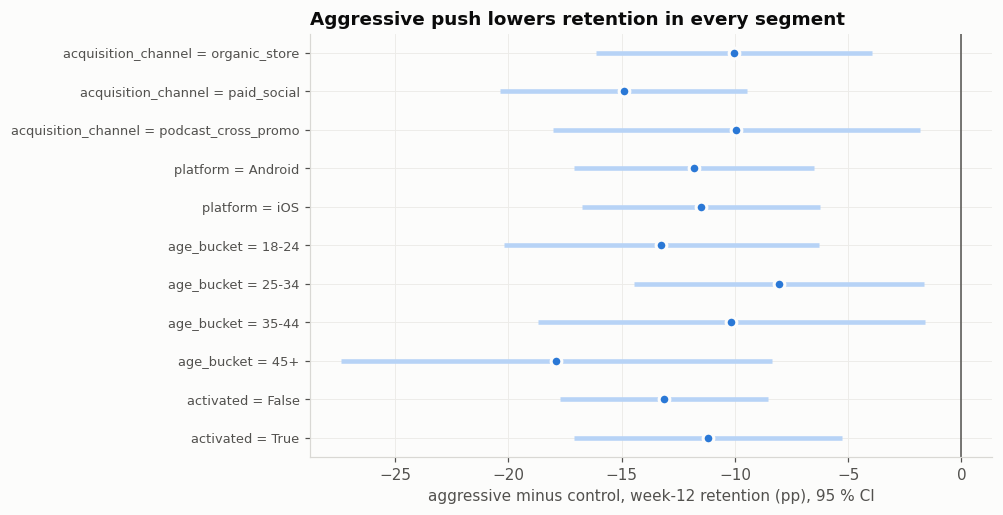

In [36]:
ut['w12'] = active_at(ut.user_id, 12)
het = []
for col in ['acquisition_channel', 'platform', 'age_bucket', 'activated']:
    for val, g in ut.groupby(col):
        c = g.loc[g.push_variant == 'control', 'w12']; a = g.loc[g.push_variant == 'aggressive_push', 'w12']
        d = a.mean() - c.mean(); se = np.sqrt(a.var() / len(a) + c.var() / len(c))
        het.append({'segment': f'{col} = {val}', 'n': len(g), 'control W12': c.mean(), 'aggressive W12': a.mean(),
                    'diff (pp)': d * 100, 'ci': 1.96 * se * 100})
het = pd.DataFrame(het)
display(het.round(3))

fig, ax = plt.subplots(figsize=(8, 5))
yy = np.arange(len(het))[::-1]
ax.errorbar(het['diff (pp)'], yy, xerr=het.ci, fmt='o', color=BLUE, ecolor='#b7d3f6', elinewidth=3, markersize=7, markeredgecolor=SURFACE, markeredgewidth=2)
ax.axvline(0, color=INK2, linewidth=1)
ax.set_yticks(yy, het.segment, fontsize=8.5)
ax.set_xlabel('aggressive minus control, week-12 retention (pp), 95 % CI')
ax.set_title('Aggressive push lowers retention in every segment')
save(fig, '07_ab_heterogeneity'); plt.show()

We can see that the effect is negative regardless of the type of users. We can highlight the fact that older people tend to be even less receptive to agressive notifications, as the paid social users which may be annoyed by the daily disturbance. 

### 7.5 What would a rollout cost? (LTV of an acquired user)

We can further our analysis by extrapolate our results of the 7.3 section to see the LTV of users. 

In [37]:
vc_std_all = value_curves(STD, min_n=200)
e_std = extend(vc_std_all)

def ab_ltv(vc, H, horizon=160):
    """Observed value for weeks 0..H, then: active share at H x standard decay shape x revenue per active week of the arm."""
    late = vc.loc[8:H]
    r_late = late.rev.sum() / late.active.sum()
    v = np.zeros(horizon); S = np.zeros(horizon)
    v[:H + 1] = vc.v.loc[:H].values; S[:H + 1] = vc.S.loc[:H].values
    rel = e_std.S.values[:horizon] / e_std.S.values[H]
    S[H + 1:] = vc.S.loc[H] * rel[H + 1:]
    v[H + 1:] = S[H + 1:] * r_late
    return pd.DataFrame({'S': S, 'v': v})

ab_ext = {arm: ab_ltv(vc, H) for arm, vc in vc_ab.items()}
res = pd.DataFrame({arm: {f'revenue weeks 0-{H} (observed)': e.v[:H + 1].sum(), 'LTV 52 weeks': e.v[:52].sum(),
                          'LTV 104 weeks': e.v[:104].sum(), 'active share week 26': e.S[26], 'active share week 52': e.S[52]}
                    for arm, e in ab_ext.items()})
res['aggressive vs control'] = res.aggressive_push / res.control - 1
display(res.style.format({'control': '{:.3f}', 'aggressive_push': '{:.3f}', 'aggressive vs control': '{:+.1%}'}))

# bootstrap CI of the observed revenue difference per user
rng = np.random.default_rng(42)
rc = full.loc[full.push_variant == 'control', 'revenue'].values; ra = full.loc[full.push_variant == 'aggressive_push', 'revenue'].values
boot = np.array([rng.choice(ra, len(ra)).mean() - rng.choice(rc, len(rc)).mean() for _ in range(5000)])
print(f'Observed revenue per user, weeks 0-{H}: diff = EUR {ra.mean() - rc.mean():+.3f}, 95 % bootstrap CI [{np.percentile(boot, 2.5):+.3f}; {np.percentile(boot, 97.5):+.3f}]')

new_per_year = u[u.signup_date >= '2025-07-01'].shape[0]
d_ltv = res.loc['LTV 104 weeks', 'aggressive_push'] - res.loc['LTV 104 weeks', 'control']
d_w26 = res.loc['active share week 26', 'aggressive_push'] - res.loc['active share week 26', 'control']
print(f'Per 10,000 new users: {d_w26 * 1e4:+,.0f} active users at week 26 and EUR {d_ltv * 1e4:+,.0f} of 2-year ad revenue')
print(f'At the last 12 months of signups ({new_per_year:,} users), new users alone: EUR {d_ltv * new_per_year:+,.0f} over 2 years')

,control,aggressive_push,aggressive vs control
revenue weeks 0-15 (observed),1.140,1.139,-0.1%
LTV 52 weeks,2.228,1.910,-14.3%
LTV 104 weeks,3.066,2.503,-18.3%
active share week 26,0.327,0.235,-28.1%
active share week 52,0.205,0.147,-28.1%


Observed revenue per user, weeks 0-15: diff = EUR -0.001, 95 % bootstrap CI [-0.045; +0.043]
Per 10,000 new users: -920 active users at week 26 and EUR -5,623 of 2-year ad revenue
At the last 12 months of signups (15,324 users), new users alone: EUR -8,616 over 2 years




## 8. North Star Metric

In [38]:
nsm = STD[STD.max_age_obs >= 11][['user_id']].copy()
agg12 = w[w.user_id.isin(nsm.user_id) & (w.age_wk <= 11)].groupby('user_id').agg(sessions=('sessions', 'sum'), minutes=('minutes', 'sum'), revenue=('revenue', 'sum'), active_weeks=('week_start', 'count'))
print('Correlation with ad revenue per user over 12 weeks (standard users):')
print(agg12.corr()['revenue'].drop('revenue').round(3).to_string())
row = w[w.push_variant != 'aggressive_push']
print('\nRow level (user-week) correlation with ad impressions: minutes', round(row.minutes.corr(row.ad_impressions), 3), '| sessions', round(row.sessions.corr(row.ad_impressions), 3))

Correlation with ad revenue per user over 12 weeks (standard users):
sessions       0.984
minutes        0.993
active_weeks   0.901

Row level (user-week) correlation with ad impressions: minutes 0.969 | sessions 0.914


| Candidate | Reflects user value? | Drives revenue? | Can be gamed? | Verdict |
|---|---|---|---|---|
| Sessions / DAU | weakly (an open is not a listen) | weakly | **yes**: the A/B test inflated it by 30 % while destroying value | vanity metric |
| WAU | partly | yes | yes (push reactivation) | good input metric |
| Ad impressions / revenue | no (it is the company's value, not the user's) | by definition | yes (more ads per hour) | business output |
| **Weekly listening hours** | **yes: listening is the core value** | **yes: ads are served at a constant 8.5 per hour** | hard: users must actually listen | **North Star** |

**North Star Metric: weekly listening hours** (total hours of podcasts listened per week across all users).

* It captures the core value: people listening to shows they chose.
* It drives revenue: in the normal regime ads are served at ~8.5 per listening hour (1 hour ≈ €0.077), and listening has the highest correlation with revenue (0.993 per user over 12 weeks).
* It is a retention-and-engagement metric, as the course recommends.
* It is hard to game. In normal times sessions also correlate with revenue (0.98), but the A/B test shows that sessions, and even short-term ad revenue, can be inflated by pushes without any extra listening. With listening hours as the primary metric, the aggressive test would have shown "flat" from day one, and "negative" by week 8.

**Metric tree (input metrics each team can own):**

```
Weekly listening hours
 = WAU  ×  listening hours per WAU
   │         └── shows followed, episode relevance, minutes per session   (content / product)
   └── WAU = new users × activation rate (>= 3 shows in week 1) × week-k retention
               │             │                                      └── relevant "new episode" pushes (CRM)
               │             └── onboarding (product)
               └── channel mix: cross-promo / organic / paid (marketing, judged on LTV:CAC)
```

Current NSM (average of the last 4 full weeks): 9,908 listening hours per week, = 7,330 WAU x 1.35 h per WAU


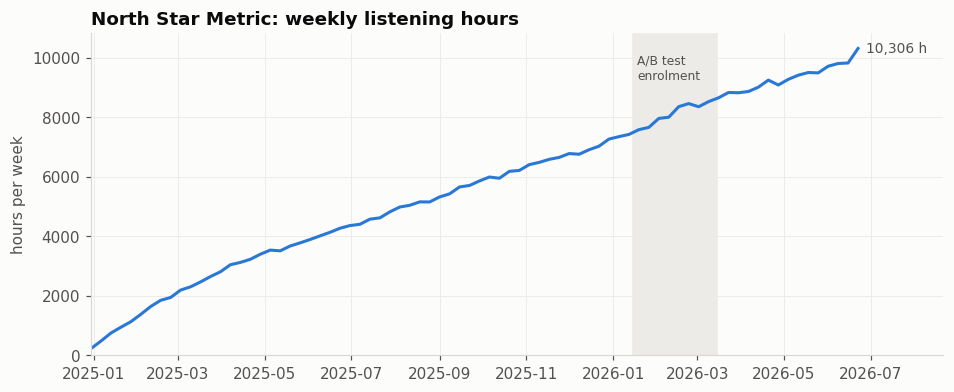

In [39]:
nsm_now = kpi['listening hours'].iloc[-4:].mean()
print(f'Current NSM (average of the last 4 full weeks): {nsm_now:,.0f} listening hours per week, '
      f'= {kpi.WAU.iloc[-4:].mean():,.0f} WAU x {kpi["minutes per WAU"].iloc[-4:].mean() / 60:.2f} h per WAU')
fig, ax = plt.subplots(figsize=(10, 3.8))
ax.plot(kpi.index, kpi['listening hours'], color=BLUE)
ax.axvspan(TEST_START, TEST_END, color='#ecebe8', zorder=0)
ax.text(TEST_START + pd.Timedelta(days=3), kpi['listening hours'].max() * 0.9, 'A/B test\nenrolment', fontsize=8, color=INK2)
end_label(ax, kpi.index[-1], kpi['listening hours'].iloc[-1], f'{kpi["listening hours"].iloc[-1]:,.0f} h')
ax.set_ylabel('hours per week'); ax.set_ylim(0); ax.set_xlim(kpi.index[0], kpi.index[-1] + pd.Timedelta(days=60))
ax.set_title('North Star Metric: weekly listening hours')
save(fig, '08_nsm'); plt.show()

## 9. Growth model: backtest and 3 scenarios

### 9.1 Model structure

The course model is $U_{t+1} = U_t\,(1 - churn) + NewUsers + Referrals$. A single churn rate does not fit Echo: churn is very high in the first weeks and low for tenured users (see the retention curves). We therefore use a **cohort model**, which is the same equation applied cohort by cohort:

$$WAU(t) = \sum_{g}\sum_{c \le t} N_{g,c}\; S_g(t-c) \qquad Revenue(t) = \sum_{g}\sum_{c \le t} N_{g,c}\; v_g(t-c)$$

* $g$ = segment = channel × activated (6 segments), $c$ = signup week, $N_{g,c}$ = new users.
* $S_g(k)$ = share of the segment active in week $k$ of life, $v_g(k)$ = ad revenue per acquired user in week $k$ (section 2.5 curves, extrapolated tail).
* **Inputs:** paid spend → paid users = spend / CAC; organic and cross-promo signups follow their log-linear trend; activation share by channel.
* **Parameters:** retention curves, revenue per active week, CAC, activation rate. **Outputs:** WAU, weekly revenue, listening hours (= revenue / €0.009 / 8.5 ads per hour).

In [40]:
GROUPS = [(ch, act) for ch in CHANNELS for act in (False, True)]

def build_curves(users_df, last_week, horizon=170):
    curves = {}
    for ch, act in GROUPS:
        g = users_df[(users_df.acquisition_channel == ch) & (users_df.activated == act) & (users_df.push_variant != 'aggressive_push')]
        curves[(ch, act)] = extend(value_curves(g, w, last_week, min_n=100), horizon)
    return curves

def existing_cohorts(users_df):
    c = users_df.groupby(['signup_week', 'acquisition_channel', 'activated']).size().rename('n').reset_index()
    return c.rename(columns={'acquisition_channel': 'channel'}).assign(kind='existing')

def fit_trends(users_df, spend_df, fit_until):
    m = users_df[users_df.signup_month <= fit_until].groupby(['signup_month', 'acquisition_channel']).size().unstack()
    t = np.arange(len(m))
    sp = spend_df[spend_df.month <= fit_until].set_index('month').spend_imputed
    return {'m0': m.index[0],
            'trends': {ch: np.polyfit(t, np.log(m[ch]), 1) for ch in ['organic_store', 'podcast_cross_promo']},
            'spend_trend': np.polyfit(t, np.log(sp.values), 1),
            'cac': (sp / m.paid_social).median(),
            'act': users_df[(users_df.signup_month <= fit_until) & (users_df.push_variant != 'aggressive_push')].groupby('acquisition_channel').activated.mean()}

def forecast_new(tr, start_day, end_day, spend_mult=1.0, act_uplift=0.0):
    days = pd.date_range(start_day, end_day, freq='D')
    month = days.to_period('M').to_timestamp()
    t = ((month.year - tr['m0'].year) * 12 + month.month - tr['m0'].month).values
    dim = days.days_in_month.values
    daily = {ch: np.exp(a + b * t) / dim for ch, (b, a) in tr['trends'].items()}
    b, a = tr['spend_trend']
    spend_daily = np.exp(a + b * t) * spend_mult / dim
    daily['paid_social'] = spend_daily / tr['cac']
    df = pd.DataFrame(daily, index=days)
    wk = df.groupby(days - pd.to_timedelta(days.dayofweek, unit='D'))[CHANNELS].sum()
    rows = []
    for sw, r in wk.iterrows():
        for ch in CHANNELS:
            p = min(tr['act'][ch] + act_uplift, 1.0)
            rows += [(sw, ch, True, r[ch] * p, 'new'), (sw, ch, False, r[ch] * (1 - p), 'new')]
    return pd.DataFrame(rows, columns=['signup_week', 'channel', 'activated', 'n', 'kind']), spend_daily.sum()

def simulate(weeks, cohorts, curves, new_ratio=None, rev_ratio=1.0, rollout=None, phi=1.0, phi_weeks=0, calib=1.0):
    weeks = pd.DatetimeIndex(weeks)
    W = np.zeros(len(weeks)); R = np.zeros(len(weeks))
    for row in cohorts.itertuples(index=False):
        c = curves[(row.channel, row.activated)]
        age = ((weeks - row.signup_week).days // 7).values
        m = (age >= 0) & (age < len(c))
        S = c.S.values[age[m]] * row.n; V = c.v.values[age[m]] * row.n
        if row.kind == 'new' and new_ratio is not None:
            f = new_ratio[np.minimum(age[m], len(new_ratio) - 1)]
            S, V = S * f, V * f * rev_ratio
        if row.kind == 'existing':
            S, V = S * calib, V * calib
            if rollout is not None:
                since = ((weeks[m] - rollout).days // 7).values + 1
                f = phi ** np.clip(since, 0, phi_weeks)
                S, V = S * f, V * f * np.where(since > 0, rev_ratio, 1.0)
        W[m] += S; R[m] += V
    return pd.DataFrame({'WAU': W, 'revenue': R}, index=weeks)

### 9.2 Backtest: calibrate on 2025, predict January - June 2026

Everything (retention curves, revenue per user, signup trends, spend trend, CAC, activation rates) is estimated **only with data available on 28 December 2025**, then the model predicts the next 26 weeks. We compare with what actually happened.

* **Backtest A (full model):** new signups are also forecast.
* **Backtest B:** actual signups are used, to isolate the error of the retention/revenue part.

,A: forecast signups,B: actual signups
MAPE WAU,+0.84%,+2.06%
MAPE revenue,+1.29%,+1.72%
"bias WAU, last week",+0.78%,+2.81%
bias 26-week revenue,-0.44%,+0.85%


Signups 29 Dec 2025 - 28 Jun 2026: forecast 8,302 vs actual 8,637 (-3.9%)


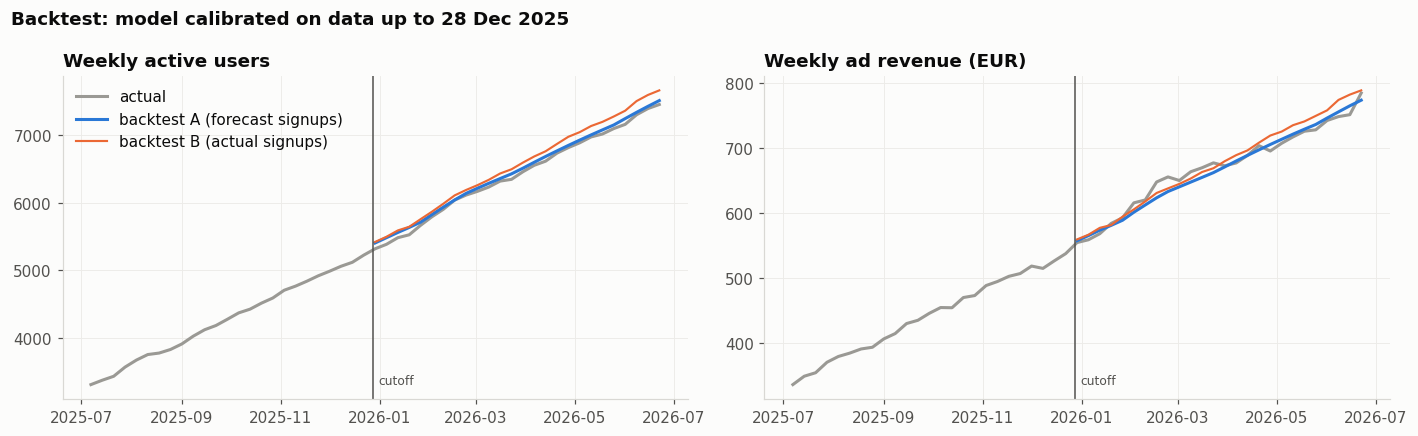

In [41]:
CUT_WEEK = pd.Timestamp('2025-12-22')          # last full week known at the cutoff
CUT_DAY = pd.Timestamp('2025-12-28')
u_train = u[u.signup_date <= CUT_DAY]
curves_bt = build_curves(u_train, CUT_WEEK)
tr_bt = fit_trends(u_train, spend, pd.Timestamp('2025-12-01'))
bt_weeks = pd.date_range('2025-12-29', LAST_FULL_WEEK, freq='W-MON')

new_bt, _ = forecast_new(tr_bt, '2025-12-29', LAST_FULL_WEEK + pd.Timedelta(days=6))
pred_A = simulate(bt_weeks, pd.concat([existing_cohorts(u_train), new_bt]), curves_bt)
actual_new = existing_cohorts(u[u.signup_date > CUT_DAY]).assign(kind='new')
pred_B = simulate(bt_weeks, pd.concat([existing_cohorts(u_train), actual_new]), curves_bt)
act = kpi.loc[bt_weeks, ['WAU', 'revenue']]

def mape(p, a): return (np.abs(p - a) / a).mean()
bt = pd.DataFrame({
    'A: forecast signups': {'MAPE WAU': mape(pred_A.WAU, act.WAU), 'MAPE revenue': mape(pred_A.revenue, act.revenue),
                            'bias WAU, last week': pred_A.WAU.iloc[-1] / act.WAU.iloc[-1] - 1, 'bias 26-week revenue': pred_A.revenue.sum() / act.revenue.sum() - 1},
    'B: actual signups': {'MAPE WAU': mape(pred_B.WAU, act.WAU), 'MAPE revenue': mape(pred_B.revenue, act.revenue),
                          'bias WAU, last week': pred_B.WAU.iloc[-1] / act.WAU.iloc[-1] - 1, 'bias 26-week revenue': pred_B.revenue.sum() / act.revenue.sum() - 1},
})
display(bt.style.format('{:+.2%}'))
sig_fore = new_bt.n.sum(); sig_act = actual_new.n.sum()
print(f'Signups 29 Dec 2025 - 28 Jun 2026: forecast {sig_fore:,.0f} vs actual {sig_act:,.0f} ({sig_fore / sig_act - 1:+.1%})')

fig, axes = plt.subplots(1, 2, figsize=(13, 4))
hist = kpi.loc['2025-07-01':]
for ax, col, title in [(axes[0], 'WAU', 'Weekly active users'), (axes[1], 'revenue', 'Weekly ad revenue (EUR)')]:
    ax.plot(hist.index, hist[col], color=GRAY, label='actual')
    ax.plot(pred_A.index, pred_A[col], color=BLUE, label='backtest A (forecast signups)')
    ax.plot(pred_B.index, pred_B[col], color=ORANGE, label='backtest B (actual signups)', linewidth=1.4)
    ax.axvline(CUT_DAY, color=INK2, linewidth=1); ax.text(CUT_DAY + pd.Timedelta(days=3), hist[col].min(), 'cutoff', fontsize=8, color=INK2)
    ax.set_title(title)
axes[0].legend(loc='upper left')
fig.suptitle('Backtest: model calibrated on data up to 28 Dec 2025', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, '09_backtest'); plt.show()

The model reproduces the first half of 2026 with **~1-2 % mean error** on WAU and revenue. Backtest B is the more informative one: with the true signups, the model **over-predicts WAU more and more after the test starts (+2.8 % by June)**. Half of the users who joined between 15 Jan and 15 Mar received aggressive push and churned faster, which a model calibrated on 2025 could not know. **The backtest error is the footprint of the A/B test.** Backtest A looks better only because two errors cancel out (signups under-forecast by 3.8 %, churn of the test cohort under-estimated).

### 9.3 Three scenarios for July 2026 → June 2027

The board's decision is the scenario variable. All scenarios start from the actual user base on 30 June 2026 (existing cohorts calibrated so that the model matches the actual WAU of the last full week).

| Scenario | Push policy | Activation | Paid spend | Assumptions from the data |
|---|---|---|---|---|
| **Pessimistic: aggressive push for everyone** | aggressive, all users | as today | trend (+3 %/month) | new users follow the aggressive/control retention ratio measured in the test (frozen after week 15) and its revenue per active week; existing users get the extra weekly loss measured in weeks 8-15 of the test, for 26 weeks |
| **Base: status quo** | normal | as today | trend | 2025-26 curves and trends continue |
| **Optimistic: guided onboarding** | normal | **+10 pp** of new users follow ≥ 3 shows | trend | moved users behave like activated users of their channel |

In [42]:
curves = build_curves(u, LAST_FULL_WEEK)
tr = fit_trends(u, spend, pd.Timestamp('2026-06-01'))
F_START, F_END = pd.Timestamp('2026-06-29'), pd.Timestamp('2027-06-21')
f_weeks = pd.date_range(F_START, F_END, freq='W-MON')
exist = existing_cohorts(u)

# calibration on the last full observed week
nowcast = simulate([LAST_FULL_WEEK], exist, curves)
CALIB = kpi.WAU.loc[LAST_FULL_WEEK] / nowcast.WAU.iloc[0]
print(f'Calibration factor for existing cohorts: {CALIB:.3f} (actual WAU {kpi.WAU.loc[LAST_FULL_WEEK]:,} vs model {nowcast.WAU.iloc[0]:,.0f})')

# parameters of the aggressive scenario, measured in the A/B test
Sc, Sa = vc_ab['control'].S.loc[:H], vc_ab['aggressive_push'].S.loc[:H]
ratio = (Sa / Sc).rolling(3, center=True, min_periods=1).mean().values
NEW_RATIO = np.concatenate([ratio, np.repeat(ratio[-1], 200)])
lc, la = vc_ab['control'].loc[2:H], vc_ab['aggressive_push'].loc[2:H]
REV_RATIO = (la.rev.sum() / la.active.sum()) / (lc.rev.sum() / lc.active.sum())
PHI = ((Sa.loc[H] / Sa.loc[8]) / (Sc.loc[H] / Sc.loc[8])) ** (1 / (H - 8))
APH_RATIO = aph['aggressive_push'] / aph['control']
print(f'Aggressive push: retention ratio at week {H} = {ratio[-1]:.2f}, revenue per active week ratio = {REV_RATIO:.3f}, '
      f'extra weekly retention factor on existing users = {PHI:.4f} (= {1 - PHI:.1%} extra loss per week)')

def run(name, act_uplift=0.0, spend_mult=1.0, aggressive=False, phi_weeks=26):
    new, spend_total = forecast_new(tr, '2026-07-01', F_END + pd.Timedelta(days=6), spend_mult, act_uplift)
    kw = dict(new_ratio=NEW_RATIO, rev_ratio=REV_RATIO, rollout=F_START, phi=PHI, phi_weeks=phi_weeks) if aggressive else {}
    sim = simulate(f_weeks, pd.concat([exist, new]), curves, calib=CALIB, **kw)
    aph = ADS_PER_HOUR * (APH_RATIO if aggressive else 1.0)    # aggressive push serves more ads per listening hour
    sim['listening hours'] = sim.revenue / REV_PER_AD / aph
    return name, sim, spend_total

scen = dict((n, (s, sp)) for n, s, sp in [
    run('Pessimistic: aggressive push for everyone', aggressive=True),
    run('Base: status quo'),
    run('Optimistic: guided onboarding (+10 pp activation)', act_uplift=0.10),
])
SC_COLORS = dict(zip(scen, [ORANGE, BLUE, AQUA]))

summ = pd.DataFrame({n: {'WAU end of June 2027': s.WAU.iloc[-1], 'average weekly listening hours (NSM)': s['listening hours'].mean(),
                         '12-month ad revenue (EUR)': s.revenue.sum(), '12-month paid spend (EUR)': sp,
                         'revenue - paid spend (EUR)': s.revenue.sum() - sp} for n, (s, sp) in scen.items()}).T
summ['revenue vs base'] = summ['12-month ad revenue (EUR)'] / summ.loc['Base: status quo', '12-month ad revenue (EUR)'] - 1
display(summ.style.format({c: '{:,.0f}' for c in summ.columns if c != 'revenue vs base'} | {'revenue vs base': '{:+.1%}'}))

Calibration factor for existing cohorts: 0.967 (actual WAU 7,457 vs model 7,708)
Aggressive push: retention ratio at week 15 = 0.72, revenue per active week ratio = 1.060, extra weekly retention factor on existing users = 0.9784 (= 2.2% extra loss per week)


,WAU end of June 2027,average weekly listening hours (NSM),12-month ad revenue (EUR),12-month paid spend (EUR),revenue - paid spend (EUR),revenue vs base
Pessimistic: aggressive push for everyone,"10,528","10,938","46,936","23,298","23,638",-16.2%
Base: status quo,"13,722","13,962","56,006","23,298","32,708",+0.0%
Optimistic: guided onboarding (+10 pp activation),"14,139","14,195","56,942","23,298","33,644",+1.7%


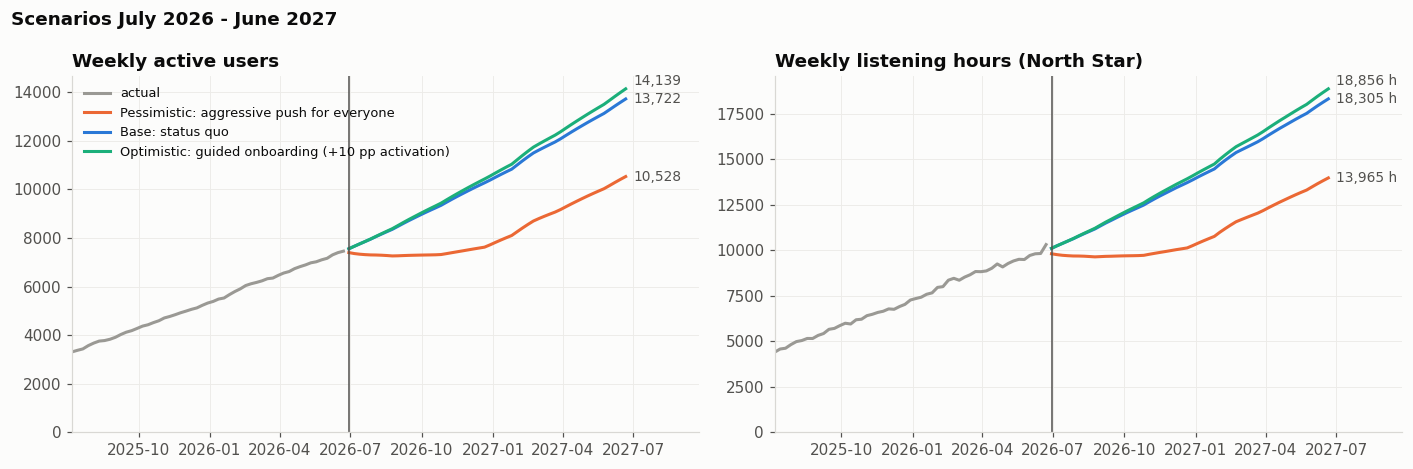

In [43]:
fig, axes = plt.subplots(1, 2, figsize=(13, 4.3))
hist = kpi.loc['2025-07-01':]
axes[0].plot(hist.index, hist.WAU, color=GRAY, label='actual')
axes[1].plot(hist.index, hist['listening hours'], color=GRAY, label='actual')
for n, (s, _) in scen.items():
    axes[0].plot(s.index, s.WAU, color=SC_COLORS[n], label=n)
    axes[1].plot(s.index, s['listening hours'], color=SC_COLORS[n], label=n)
axes[0].set_title('Weekly active users'); axes[1].set_title('Weekly listening hours (North Star)')
for ax in axes:
    ax.axvline(F_START, color=INK2, linewidth=1); ax.set_xlim(hist.index[0], F_END + pd.Timedelta(days=95)); ax.set_ylim(0)
lx = F_END + pd.Timedelta(days=10)
end_labels(axes[0], lx, [(s.WAU.iloc[-1], f'{s.WAU.iloc[-1]:,.0f}') for s, _ in scen.values()])
end_labels(axes[1], lx, [(s['listening hours'].iloc[-1], f'{s["listening hours"].iloc[-1]:,.0f} h') for s, _ in scen.values()])
axes[0].legend(loc='upper left', fontsize=8.5)
fig.suptitle('Scenarios July 2026 - June 2027', x=0.01, ha='left', fontweight='bold')
fig.tight_layout(); save(fig, '09_scenarios'); plt.show()

### 9.4 What-if experiments: one parameter at a time (course slide 98)

Sensitivity of the 12-month outcome to each lever, plus the key uncertainty of the pessimistic scenario (how long existing users keep eroding under aggressive push).

In [44]:
whatif = [
    ('Base', {}),
    ('Aggressive push, new users only', dict(aggressive=True, phi_weeks=0)),
    ('Aggressive push, existing users erode 26 weeks', dict(aggressive=True, phi_weeks=26)),
    ('Aggressive push, existing users erode 52 weeks', dict(aggressive=True, phi_weeks=52)),
    ('Activation +5 pp', dict(act_uplift=0.05)),
    ('Activation +10 pp', dict(act_uplift=0.10)),
    ('Paid social spend x 1.5', dict(spend_mult=1.5)),
    ('Paid social stopped', dict(spend_mult=0.0)),
]
wi = {}
for name, kw in whatif:
    _, s, sp = run(name, **kw)
    wi[name] = {'WAU June 2027': s.WAU.iloc[-1], '12-month revenue': s.revenue.sum(), '12-month paid spend': sp,
                'revenue - spend': s.revenue.sum() - sp}
wi = pd.DataFrame(wi).T
wi['delta (revenue - spend) vs base'] = wi['revenue - spend'] - wi.loc['Base', 'revenue - spend']
display(wi.style.format('{:,.0f}'))

,WAU June 2027,12-month revenue,12-month paid spend,revenue - spend,delta (revenue - spend) vs base
Base,"13,722","56,006","23,298","32,708",0
"Aggressive push, new users only","11,857","54,641","23,298","31,343","-1,365"
"Aggressive push, existing users erode 26 weeks","10,528","46,936","23,298","23,638","-9,070"
"Aggressive push, existing users erode 52 weeks","9,775","45,616","23,298","22,318","-10,390"
Activation +5 pp,"13,931","56,474","23,298","33,176",468
Activation +10 pp,"14,139","56,942","23,298","33,644",935
Paid social spend x 1.5,"15,141","60,895","34,947","25,948","-6,760"
Paid social stopped,"10,884","46,228",0,"46,228","13,520"


In [45]:
# value of activation: 2-year LTV per acquired user by channel and activation (model curves)
ltv_seg = pd.DataFrame({ch: {'not activated': curves[(ch, False)].v[:104].sum(), 'activated (>= 3 shows)': curves[(ch, True)].v[:104].sum()} for ch in CHANNELS}).T
ltv_seg['value of activating one user'] = ltv_seg['activated (>= 3 shows)'] - ltv_seg['not activated']
ltv_seg['activated LTV / paid CAC'] = ltv_seg['activated (>= 3 shows)'] / CAC_PAID
display(ltv_seg.round(2))

,not activated,activated (>= 3 shows),value of activating one user,activated LTV / paid CAC
organic_store,2.750,4.600,1.850,1.770
paid_social,1.590,3.330,1.740,1.280
podcast_cross_promo,3.310,5.420,2.110,2.080


Reading the scenarios and the what-if table:

* **Aggressive push is the worst option in every variant.** Even if only new users are affected, it costs WAU (−14 % in June 2027) and revenue. If existing users also erode, 12-month revenue falls by 16-18 % and WAU by 23-29 %.
* **Activation helps, but slowly.** +10 pp of new users following 3 shows adds only +1.7 % of revenue in the first 12 months, because 12-month revenue is dominated by the users Echo already has. It compounds: each extra activated user is worth €1.75-2.11 more over 2 years (table above), at no media cost.
* **Paid social destroys value at the margin.** +50 % budget adds €4.9k of revenue for €11.8k of spend. Stopping it would cut WAU by 21 % but improve "revenue − spend" by €13.7k over 12 months, because a paid user returns only ~60 % of its CAC in its first year and ~78 % in two years. Paid social is still the volume engine, so the recommendation is to **fix it before cutting it**. The table above shows why it can be fixed: an *activated* paid user is worth €3.33 over 2 years and pays back its €2.61 CAC, a non-activated one (75 % of paid signups) is worth €1.59 and never does. Target audiences likely to follow shows, onboard them to 3 shows, and cap CAC at the 2-year LTV (~€2.0 today, lower once costs are included).

## 10. A/B test plan: the next experiment

The data points to activation as the biggest lever, so the next test should not be about more notifications but about better onboarding.

We will analyse the power of the new following A/B test, based on the activation (the number of podcasts the user is following).

In [46]:
def n_per_arm(p1, mde, alpha=0.05, power=0.8):
    p2 = p1 + mde; pbar = (p1 + p2) / 2
    za, zb = stats.norm.ppf(1 - alpha / 2), stats.norm.ppf(power)
    return int(np.ceil((za * np.sqrt(2 * pbar * (1 - pbar)) + zb * np.sqrt(p1 * (1 - p1) + p2 * (1 - p2))) ** 2 / mde ** 2))

base_w8 = active_at(STD[STD.max_age_obs >= 8].user_id, 8).mean()
base_act = STD.activated.mean()
weekly_signups = u[u.signup_date >= '2026-04-01'].shape[0] / ((EXTRACTION - pd.Timestamp('2026-04-01')).days / 7)
plan = []
for metric, p, mde in [('week-8 retention (primary)', base_w8, 0.03), ('week-8 retention (primary)', base_w8, 0.04),
                       ('activation >= 3 shows (secondary)', base_act, 0.05)]:
    n = n_per_arm(p, mde)
    plan.append({'metric': metric, 'baseline': p, 'MDE (pp)': mde * 100, 'users per arm': n,
                 'enrolment weeks (50/50 of all signups)': 2 * n / weekly_signups})
display(pd.DataFrame(plan).round(2))
print(f'Current signups per week: {weekly_signups:,.0f}')

,metric,baseline,MDE (pp),users per arm,enrolment weeks (50/50 of all signups)
0,week-8 retention (primary),0.610,3.000,4073,23.300
1,week-8 retention (primary),0.610,4.000,2278,13.030
2,activation >= 3 shows (secondary),0.380,5.000,1510,8.640


Current signups per week: 350


Test: "Pick 3 shows" guided onboarding

We saw that the more an user is following different shows, the less he is susceptible to gave up the app. To maximize the retention: we could believe that making people selecting for at least 3 podcasts to follow when they sign up should make them stay on the app for a longer time.

## 11. Conclusion

No, Echo should not roll out aggressive push notifications to everyone. The "+30 % sessions" is a vanity metric: aggressive users open the app more but don't listen more, and from week 8 they churn faster (−12 pp of retention at week 12, gap still widening), in every segment. Rolled out to everyone, it would cut 12-month revenue by 16-18 % and WAU by 23-29 %.

The real levers are elsewhere:
* Steer on weekly listening hours (North Star), not sessions.
* Activation: users following 3+ shows in week 1 retain far better, but only 38 % get there today. The "Pick 3 shows" onboarding test is the next experiment to run.
* Fix paid social before scaling it: LTV:CAC ≈ 0.78 today, but an activated paid user pays back its CAC (€3.33 vs €2.61). Better targeting and onboarding beat a bigger budget.